# 04 — Feature Engineering (v2) & Comprehensive Feature EDA
**Stock-Market-ML-Predictor v3**  
**Asset:** BTCUSDT | **Candle Frequency:** 5-minute  
**Dataset:** `master.csv` (TRAIN partition: 2023-11-01 to 2025-12-07, $N=220,953$ candles, 85 engineered features)  
**Strict Safety Rules:**  
- Evaluated **exclusively on the training partition**. Validation and test partitions are strictly isolated to prevent leakage and data snooping.  
- Test split remains **100% locked**.  
- All interpretations are **computed dynamically from data tables** (no hardcoded manual metrics, zero untyped claims).  
- **Descriptive & Exploratory only:** Pruning candidates and correlation clusters serve strictly as inputs for Step 5 walk-forward cross-validation ablation. Setup and horizon selection are decided strictly in Step 5.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure local src/ imports resolve cleanly
ML_DIR = Path.cwd()
if ML_DIR.name != "ML":
    ML_DIR = ML_DIR / "ML"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import config
from src.column_dictionary import load_master, get_feature_columns, get_column_role
from src.features import FEATURE_GROUPS
from src.feat_eda import (
    verify_train_only,
    compute_feature_inventory,
    compute_feature_statistics_table,
    compute_feature_correlations,
    compute_feature_vif,
    compute_size_side_metrics,
    compute_direction_side_metrics,
    compute_direction_quarterly_stability,
    compute_context_analysis,
    compute_quarterly_drift,
    compute_correlation_clusters,
    compute_breakeven_table,
)
from src.plotting import (
    plot_feature_group_histograms,
    plot_feature_correlations_clustered,
    plot_feature_group_correlation_heatmaps,
    plot_size_auc_ranked_bars,
    plot_size_cohens_d_heatmap,
    plot_direction_metrics_heatmap,
    plot_lagged_flow_loc,
    plot_rolling_direction_correlation,
    plot_direction_quarterly_stability,
    plot_context_profiles,
    plot_acf_deseasoning,
)

# 1. Safe Load of Train Partition
print("Loading master.csv TRAIN partition...")
df_train = load_master(split="train")
verify_train_only(df_train)

feature_cols = get_feature_columns(df_train)
print(f"✓ Train partition loaded successfully: {len(df_train):,} rows × {len(df_train.columns)} columns")
print(f"✓ Verified feature count: {len(feature_cols)} features across {len(FEATURE_GROUPS)} groups.")


Loading master.csv TRAIN partition...


✓ Train partition loaded successfully: 220,953 rows × 172 columns
✓ Verified feature count: 85 features across 15 groups.


## Section 1: Feature Inventory & Warm-Up Validation
Inventory of all 85 engineered features across 15 feature groups, specifying causal mathematical formulas, units, warm-up requirements (`LOOKBACK_CANDLES = 2018`), and train NaN fractions.


In [2]:
# Compute feature inventory
df_inv, group_counts = compute_feature_inventory(df_train)

print(f"=== FEATURE INVENTORY SUMMARY ({len(df_inv)} FEATURES) ===")
print("\nFeature Counts by Group:")
for grp, cnt in group_counts.items():
    print(f"  {grp:15s}: {cnt:2d} features")

print(f"\nWarm-up requirement: LOOKBACK_CANDLES = {config.LOOKBACK_CANDLES} candles ({(config.LOOKBACK_CANDLES*5)/(60*24):.2f} days)")
print(f"Live buffer size:    LIVE_BUFFER_CANDLES = {config.LIVE_BUFFER_CANDLES} candles ({(config.LIVE_BUFFER_CANDLES*5)/(60*24):.2f} days)")

print("\nSample Inventory Records (First 10 features):")
display(df_inv[["feature", "group", "unit", "warmup_candles", "nan_count_train", "zero_share_train"]].head(10))

# Dynamic Interpretation
post_warmup_nans = df_train.iloc[config.LOOKBACK_CANDLES:][feature_cols].isna().sum().sum()
print(f"\nInterpretation: All {len(df_inv)} features are strictly populated with 0 NaNs after warm-up row {config.LOOKBACK_CANDLES} (Post-warmup NaNs = {post_warmup_nans}).")


2026-11-11 18:15:24 | INFO     | feat_eda | Saved feature inventory to C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\reports\feat_inventory.csv (85 features)


=== FEATURE INVENTORY SUMMARY (85 FEATURES) ===

Feature Counts by Group:
  momentum       : 13 features
  volatility     :  9 features
  candle_shape   :  6 features
  order_flow     :  6 features
  vol_range      :  6 features
  vol_realized   :  6 features
  flow_window    :  6 features
  returns        :  5 features
  volume         :  5 features
  mtf_1h         :  5 features
  time           :  4 features
  vol_seasonal   :  4 features
  vol_har        :  4 features
  location       :  3 features
  time_weekend   :  3 features

Warm-up requirement: LOOKBACK_CANDLES = 2018 candles (7.01 days)
Live buffer size:    LIVE_BUFFER_CANDLES = 2880 candles (10.00 days)

Sample Inventory Records (First 10 features):


,feature,group,unit,warmup_candles,nan_count_train,zero_share_train
0,feat_ret_1,returns,fraction,2018,1,0.002494
1,feat_ret_3,returns,fraction,2018,3,0.000539
2,feat_ret_6,returns,fraction,2018,6,0.000267
3,feat_ret_12,returns,fraction,2018,13,0.000213
4,feat_ret_24,returns,fraction,2018,24,0.000163
5,feat_vol_sigma_288,volatility,fraction,2018,287,0.000000
6,feat_vol_sigma_60,volatility,fraction,2018,71,0.000000
7,feat_vol_sigma_12,volatility,fraction,2018,13,0.000000
8,feat_vol_ratio_60_288,volatility,ratio,2018,287,0.000000
9,feat_vol_ratio_12_60,volatility,ratio,2018,71,0.000000



Interpretation: All 85 features are strictly populated with 0 NaNs after warm-up row 2018 (Post-warmup NaNs = 0).


## Section 2: Full Variable Statistics Table (Train Only)
Summary statistics computed on valid post-warmup training rows ($N = 218,935$ candles): count, mean, std, quantiles (1%, 5%, 25%, median, 75%, 95%, 99%), min, max, skewness, excess kurtosis, zero share, and 5-robust-sigma outlier frequency.


In [3]:
# Compute full statistics table
df_stats = compute_feature_statistics_table(df_train, warmup_candles=config.LOOKBACK_CANDLES)

print("=== FEATURE SUMMARY STATISTICS TABLE (Top 15 Features by Variance) ===")
display(df_stats[["feature", "group", "mean", "std", "min", "median", "max", "skew", "excess_kurtosis", "share_beyond_5_robust_sigma"]].head(15))

# Check for near-constant features
near_constant_df = df_stats[df_stats["is_near_constant"]]
print(f"\nNear-constant features detected (std < 1e-6 or mode share > 95%): {len(near_constant_df)}")
if len(near_constant_df) > 0:
    display(near_constant_df[["feature", "group", "std", "top_val_share"]])

# Top fat-tailed features
top_kurt = df_stats.sort_values(by="excess_kurtosis", ascending=False).head(5)
print("\nTop 5 Fat-Tailed Features (Excess Kurtosis):")
for _, r in top_kurt.iterrows():
    print(f"  {r['feature']:35s} ({r['group']:12s}): Kurtosis = {r['excess_kurtosis']:8.2f} | 5-sigma Outliers = {r['share_beyond_5_robust_sigma']*100:.3f}%")

med_kurt = df_stats['excess_kurtosis'].median()
mean_5sig = df_stats['share_beyond_5_robust_sigma'].mean() * 100
print(f"\nInterpretation: Median feature excess kurtosis across all {len(df_stats)} features is {med_kurt:.2f}, with an average of {mean_5sig:.3f}% of values beyond 5 robust sigmas, demonstrating non-Gaussian heavy tails characteristic of high-frequency cryptocurrency dynamics.")


2026-11-11 18:15:46 | INFO     | feat_eda | Saved feature statistics table to C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\reports\feat_variable_statistics.csv (85 rows)


=== FEATURE SUMMARY STATISTICS TABLE (Top 15 Features by Variance) ===


,feature,group,mean,std,min,median,max,skew,excess_kurtosis,share_beyond_5_robust_sigma
0,feat_ret_1,returns,0.000004,0.001531,-0.076213,0.000000,0.040005,-0.872018,58.724196,0.013712
1,feat_ret_3,returns,0.000013,0.002611,-0.101318,0.000005,0.068420,-0.610980,32.622191,0.014319
2,feat_ret_6,returns,0.000025,0.003664,-0.117087,0.000026,0.084158,-0.465731,23.135915,0.015808
3,feat_ret_12,returns,0.000051,0.005145,-0.116070,0.000059,0.085125,-0.369672,15.365855,0.017457
4,feat_ret_24,returns,0.000102,0.007216,-0.114440,0.000159,0.087583,-0.213379,11.235298,0.017133
5,feat_vol_sigma_288,volatility,0.001384,0.000654,0.000271,0.001265,0.006770,2.074233,8.807027,0.009167
6,feat_vol_sigma_60,volatility,0.001311,0.000792,0.000161,0.001124,0.012887,2.986459,21.161027,0.012748
7,feat_vol_sigma_12,volatility,0.001239,0.000906,0.000055,0.001013,0.028915,4.614194,64.553440,0.017407
8,feat_vol_ratio_60_288,volatility,0.958719,0.320481,0.139143,0.922731,2.159178,0.498615,-0.094721,0.000000
9,feat_vol_ratio_12_60,volatility,0.958545,0.326456,0.134481,0.911091,2.294632,0.703327,0.358576,0.000000



Near-constant features detected (std < 1e-6 or mode share > 95%): 0

Top 5 Fat-Tailed Features (Excess Kurtosis):
  feat_vol_seasonal_volume_ratio_7d   (vol_seasonal): Kurtosis =   770.41 | 5-sigma Outliers = 4.618%
  feat_shape_lower_wick_pct           (candle_shape): Kurtosis =   298.81 | 5-sigma Outliers = 2.850%
  feat_volume_change_1                (volume      ): Kurtosis =   292.29 | 5-sigma Outliers = 2.833%
  feat_vol_seasonal_trades_ratio_7d   (vol_seasonal): Kurtosis =   266.57 | 5-sigma Outliers = 2.846%
  feat_shape_body_pct                 (candle_shape): Kurtosis =   162.80 | 5-sigma Outliers = 2.611%

Interpretation: Median feature excess kurtosis across all 85 features is 8.81, with an average of 1.146% of values beyond 5 robust sigmas, demonstrating non-Gaussian heavy tails characteristic of high-frequency cryptocurrency dynamics.


## Section 3: Feature Group Distribution Histograms
Empirical probability distributions across all 15 feature groups, capturing skewness, multi-modality, and bounding behaviors. Saved directly to `results/figures/04_dist_<group>.png`.


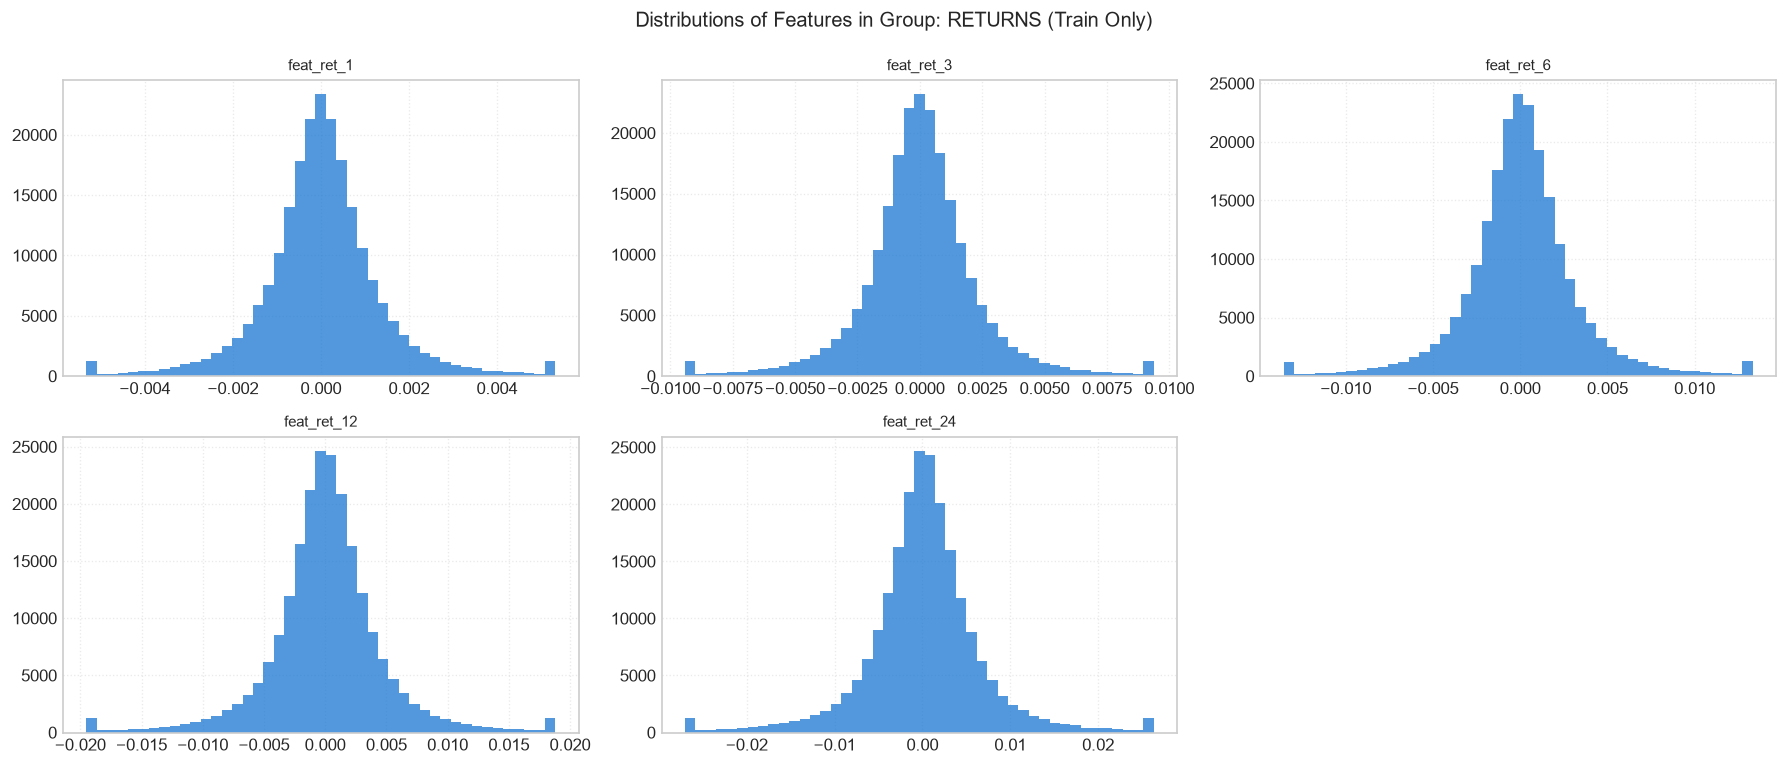

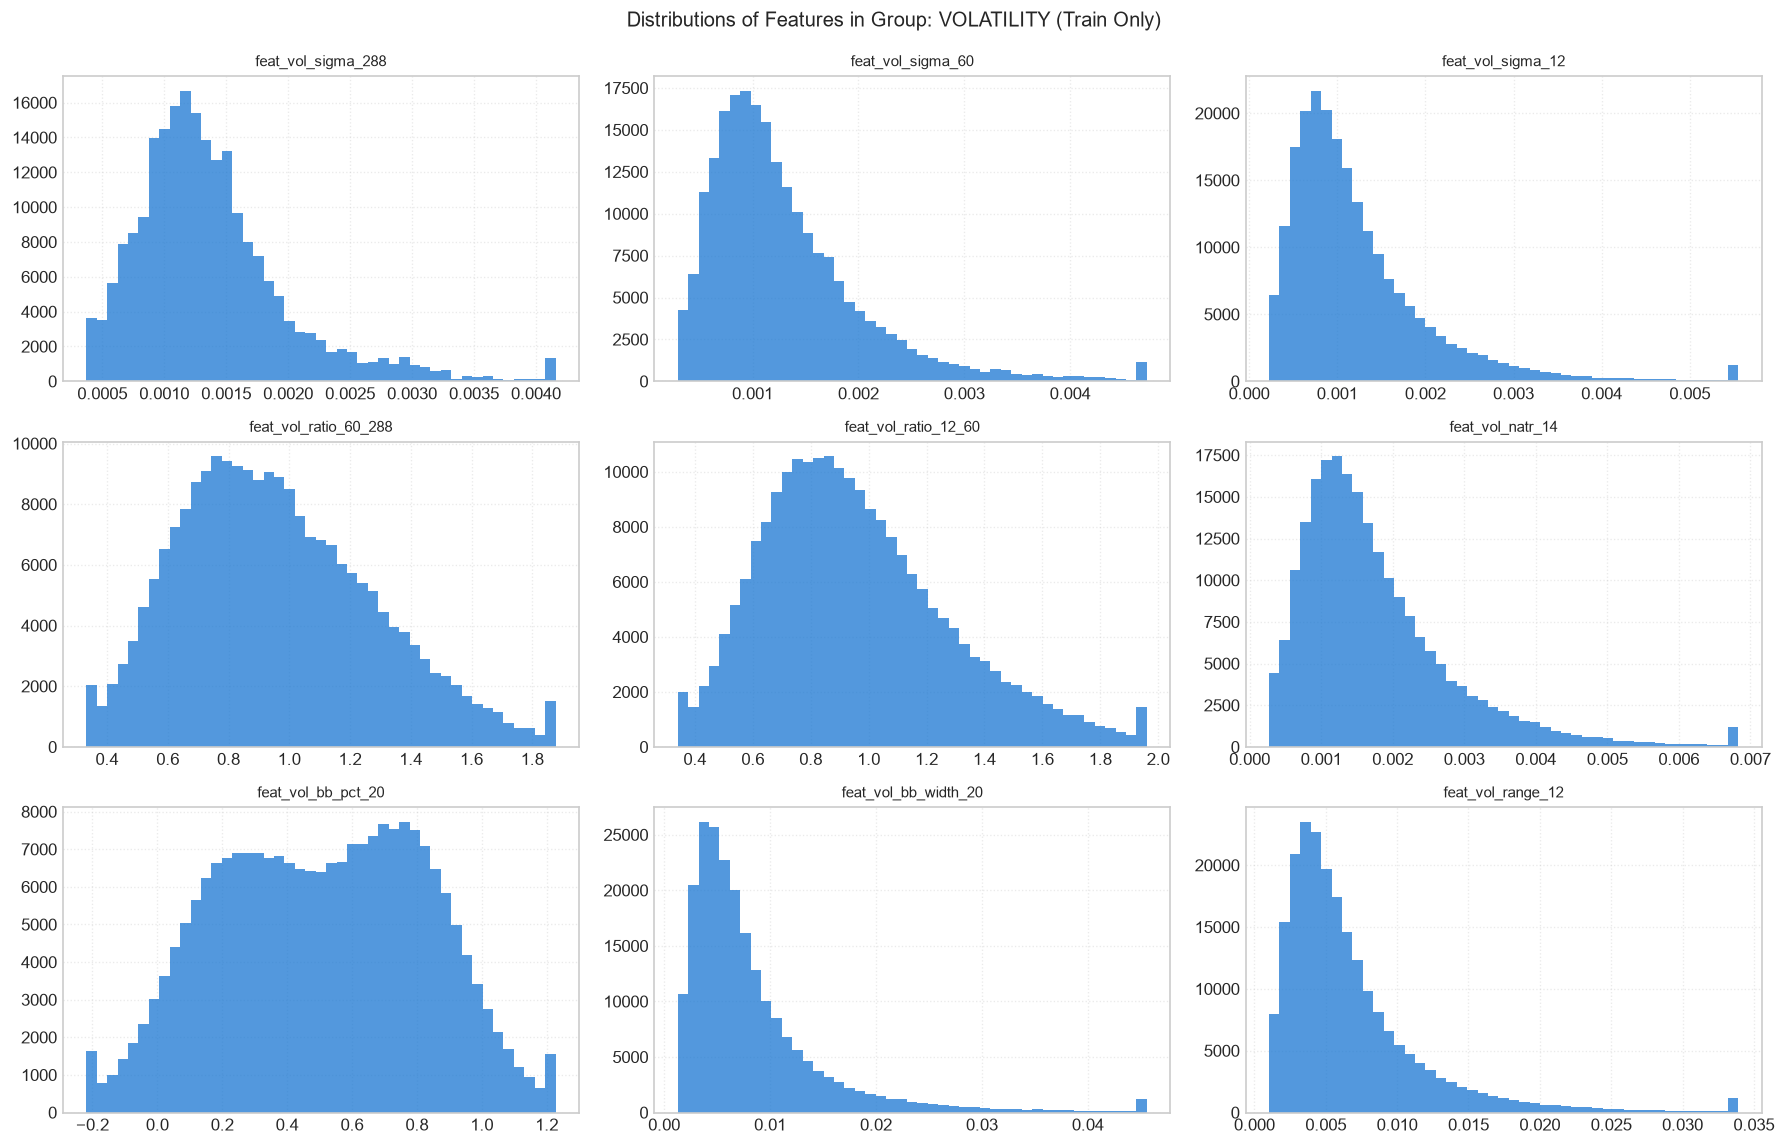

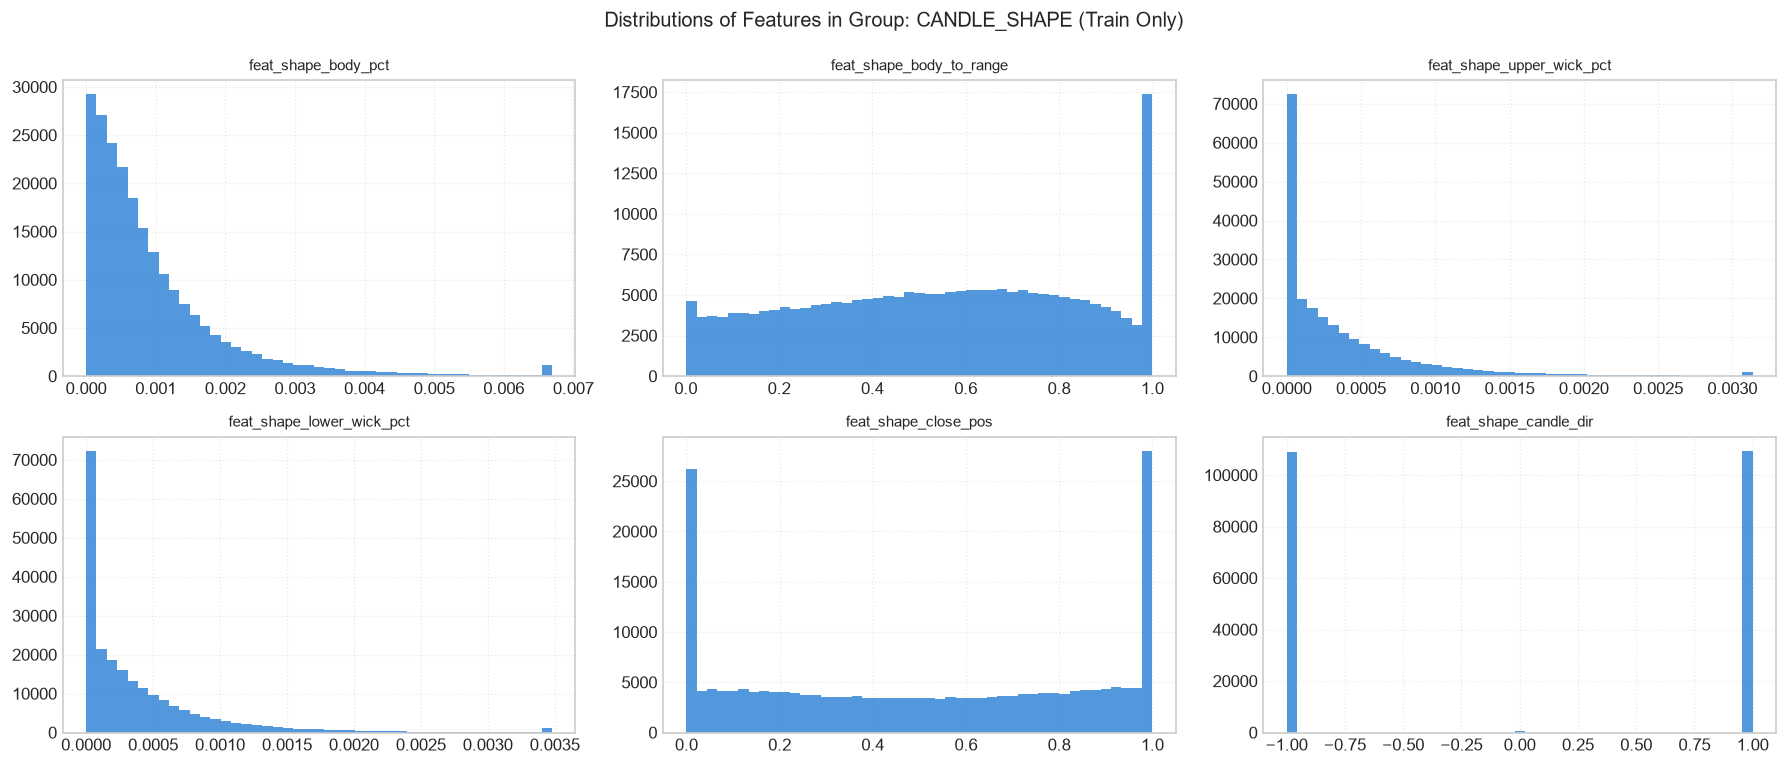

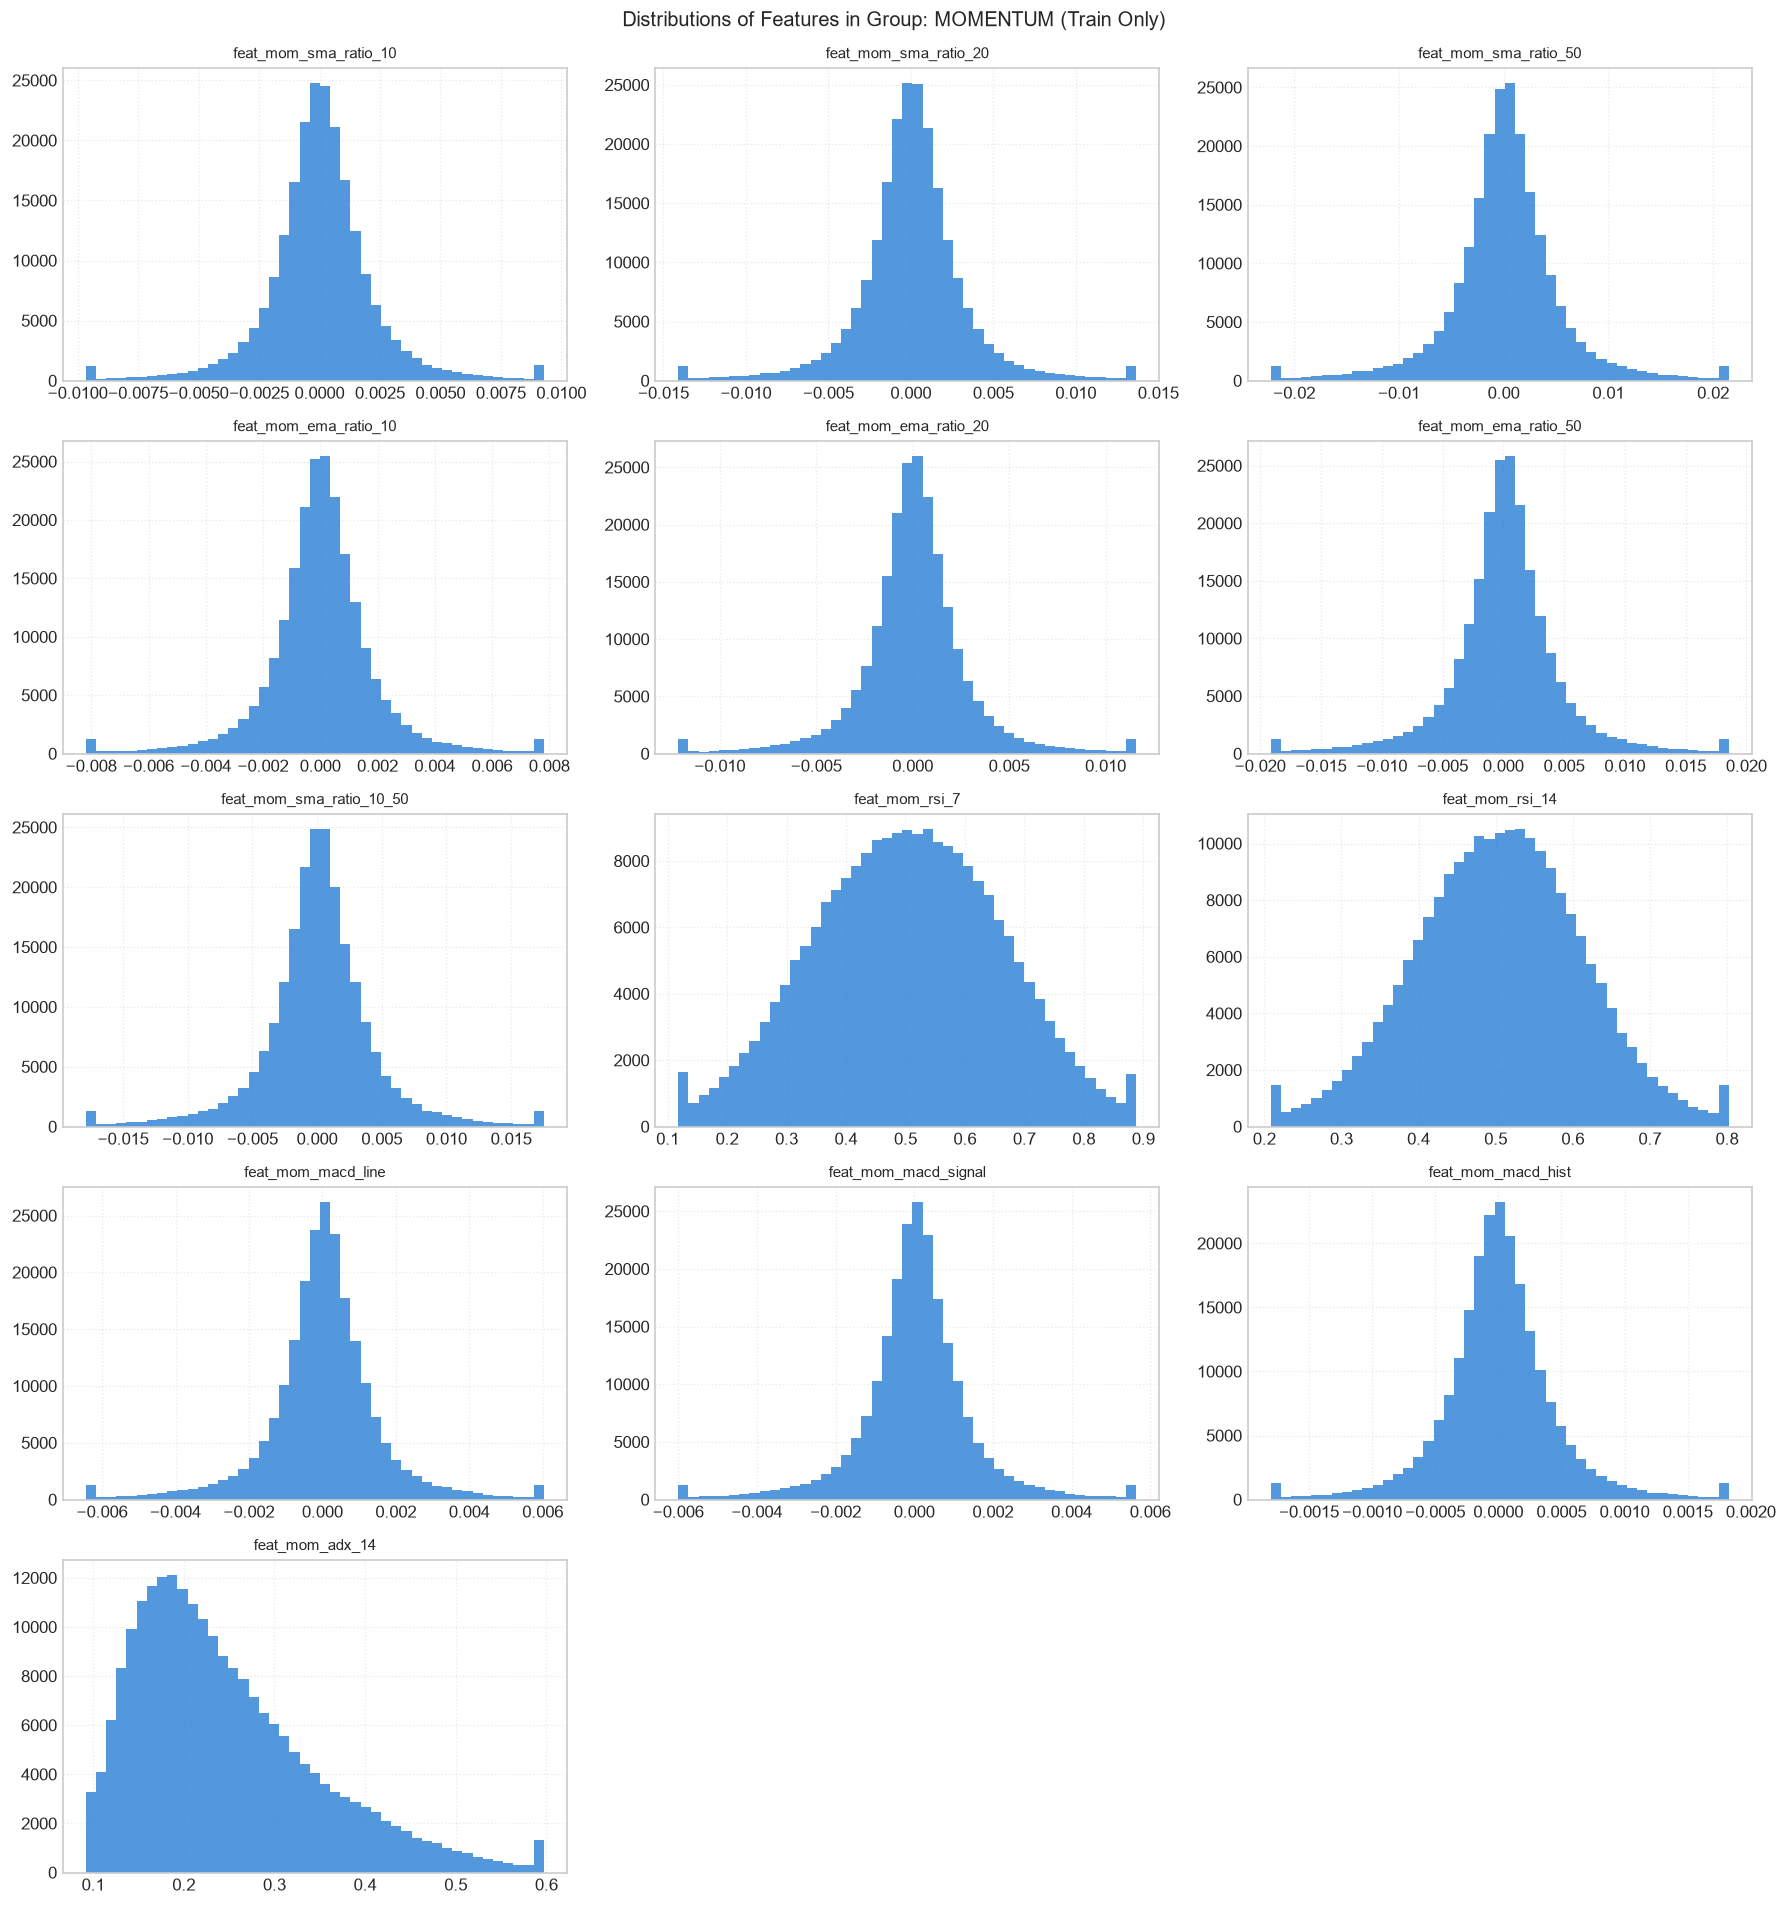

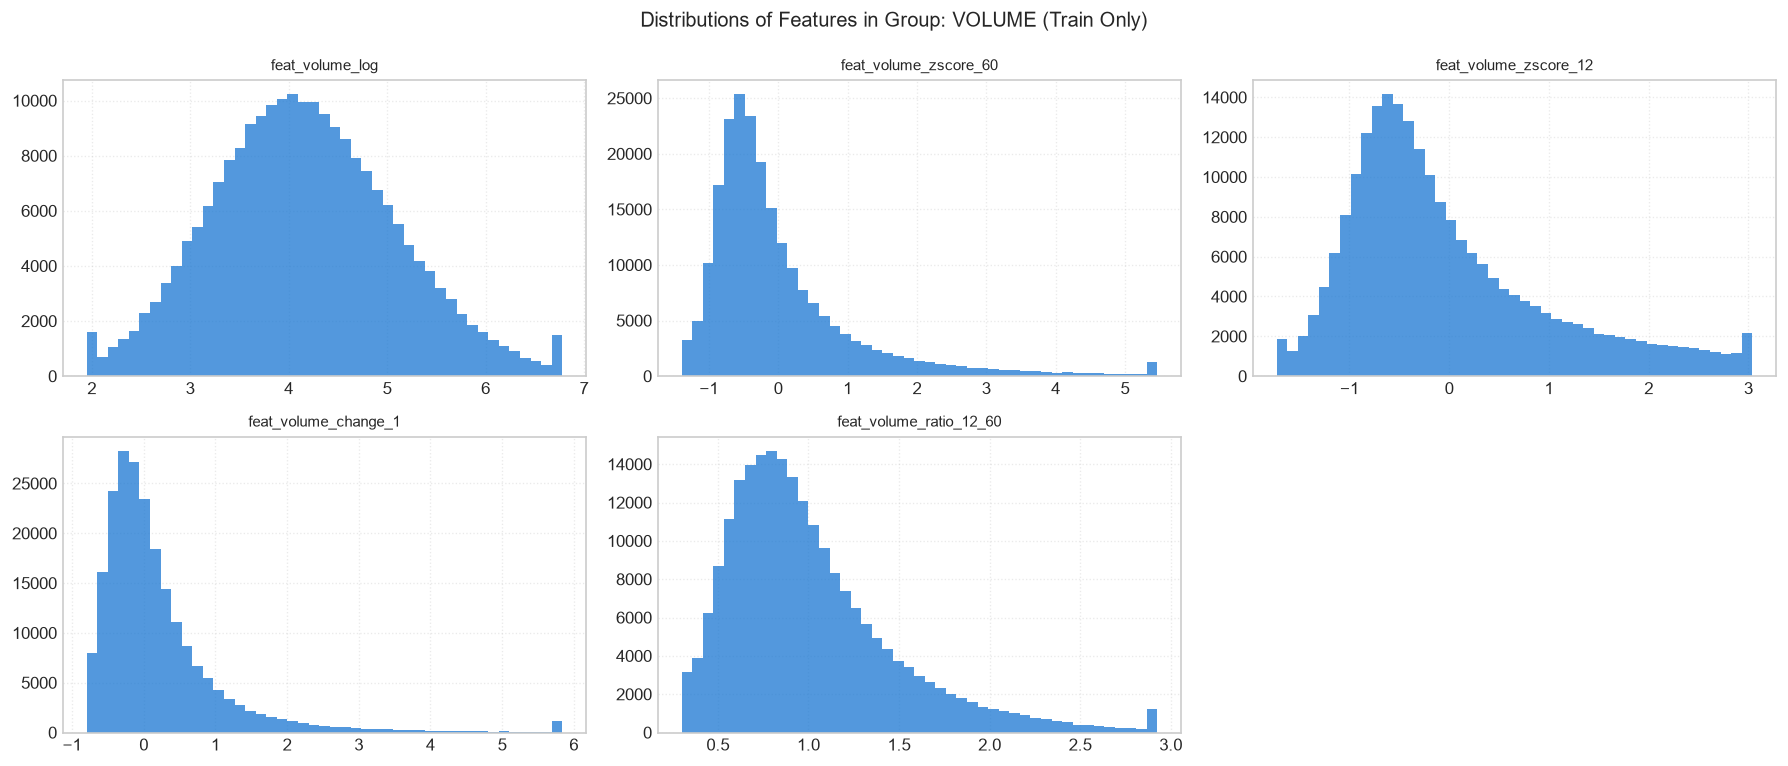

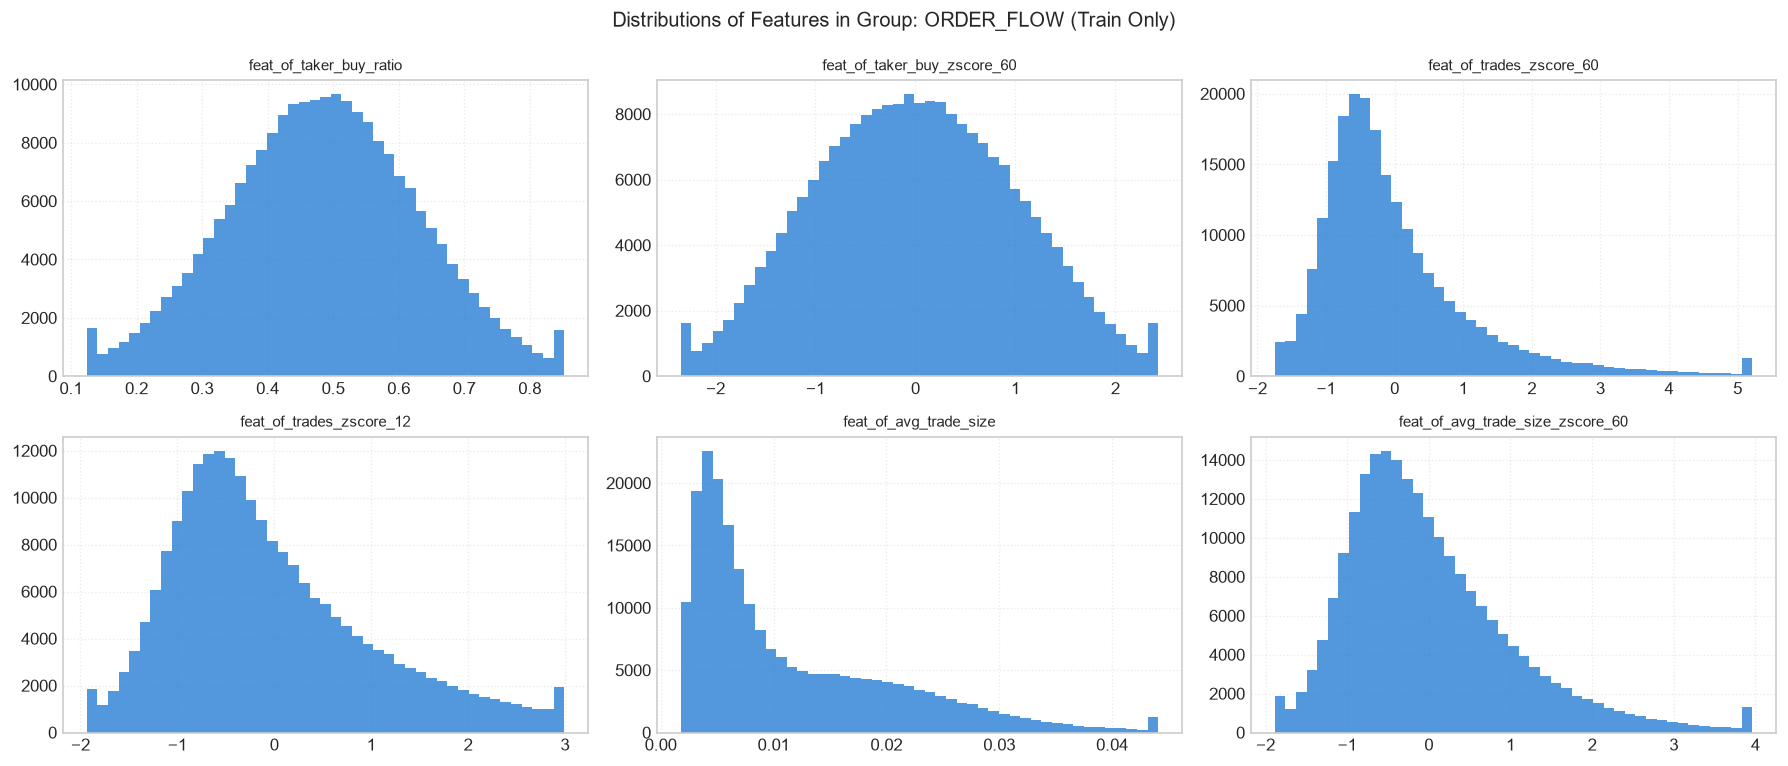

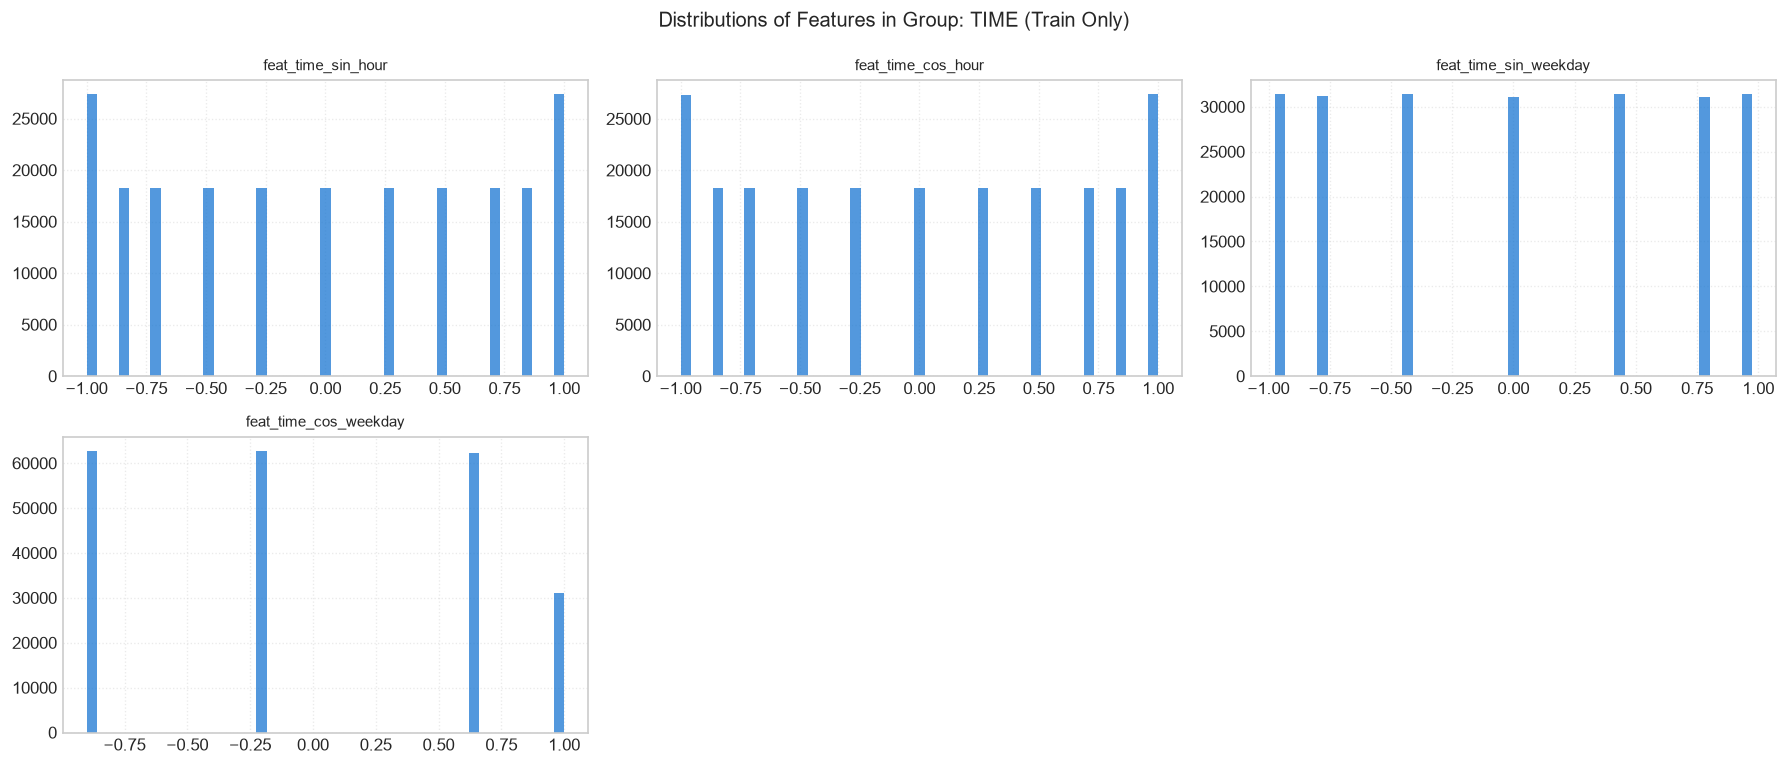

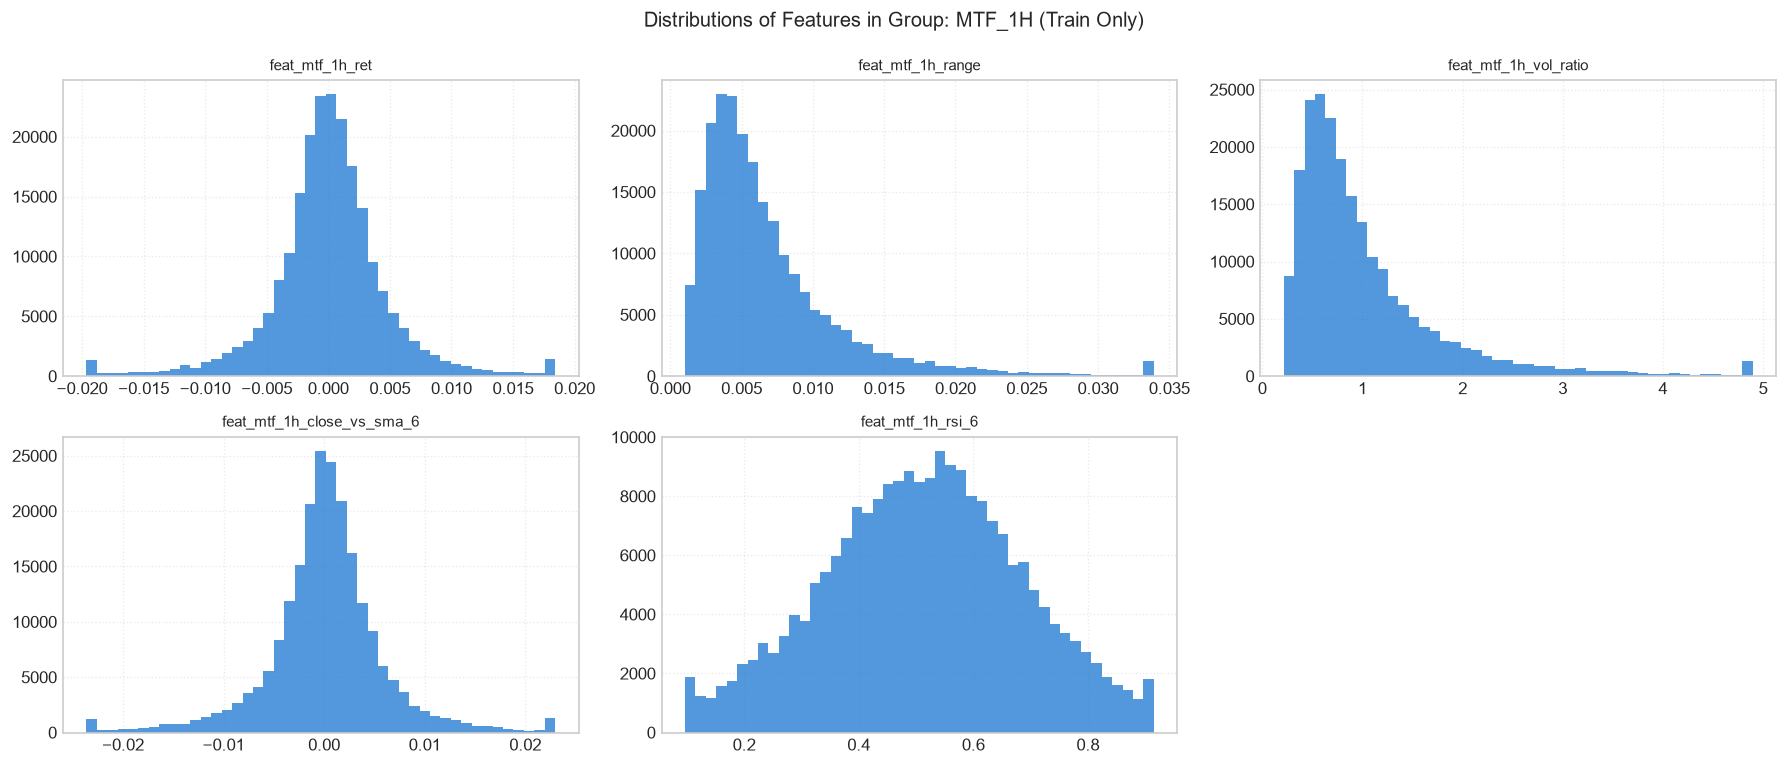

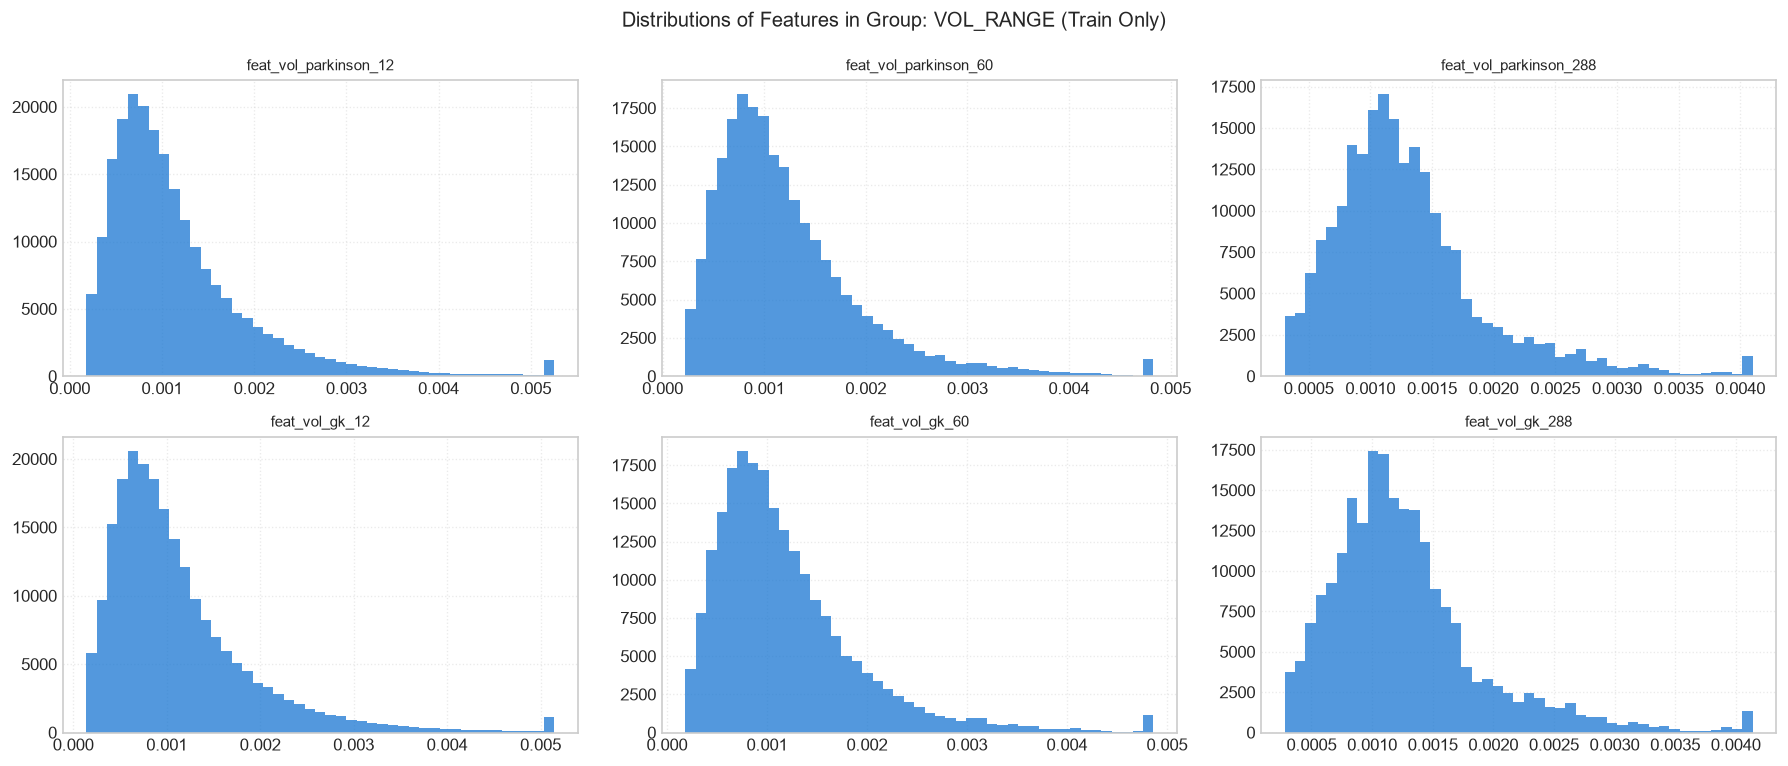

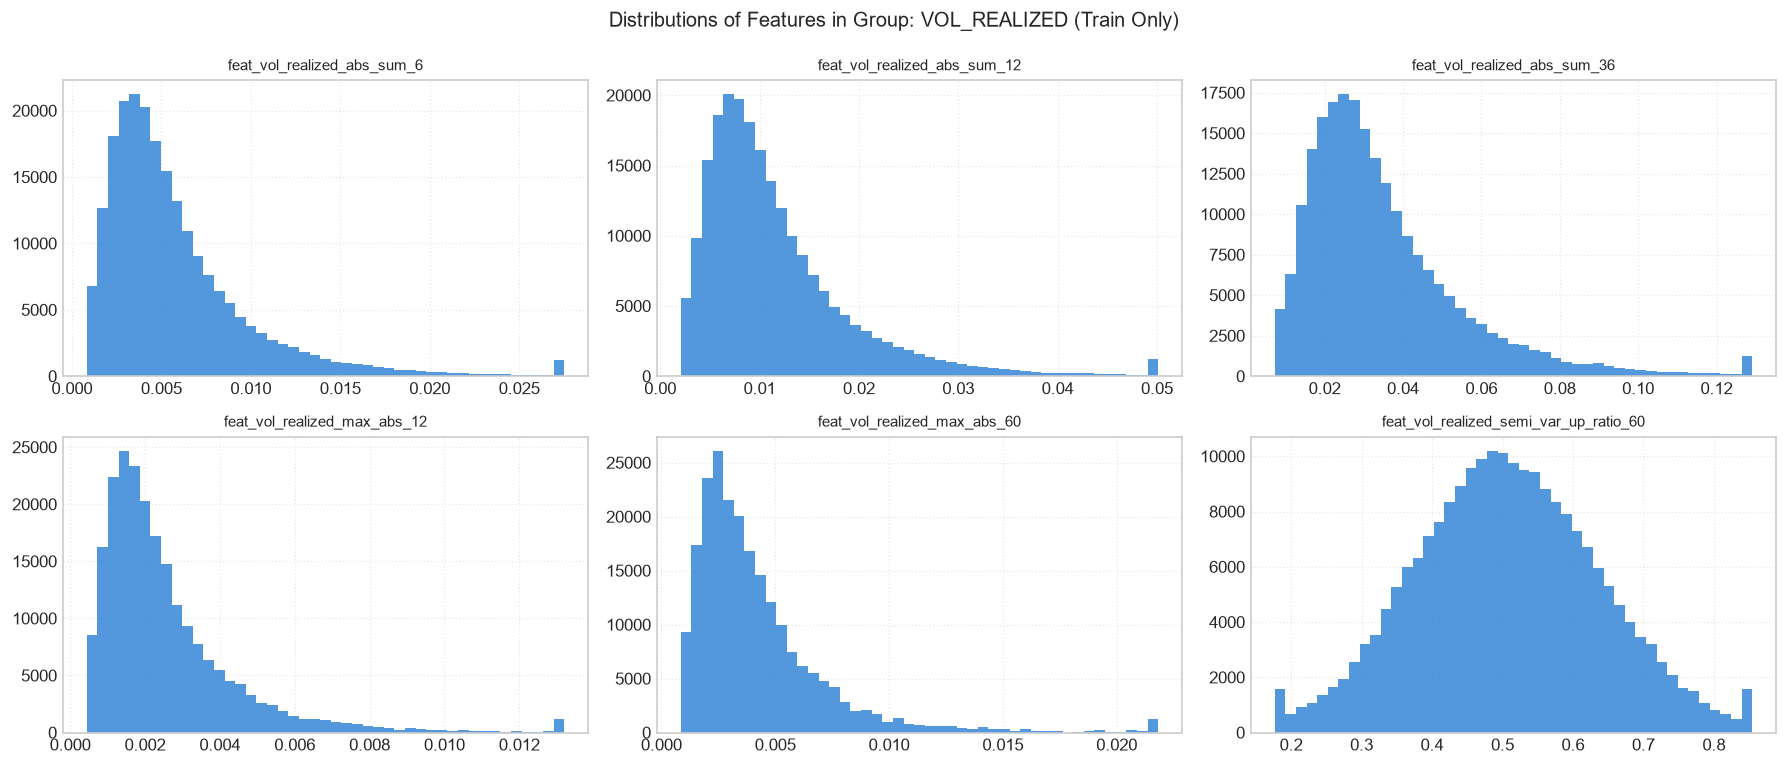

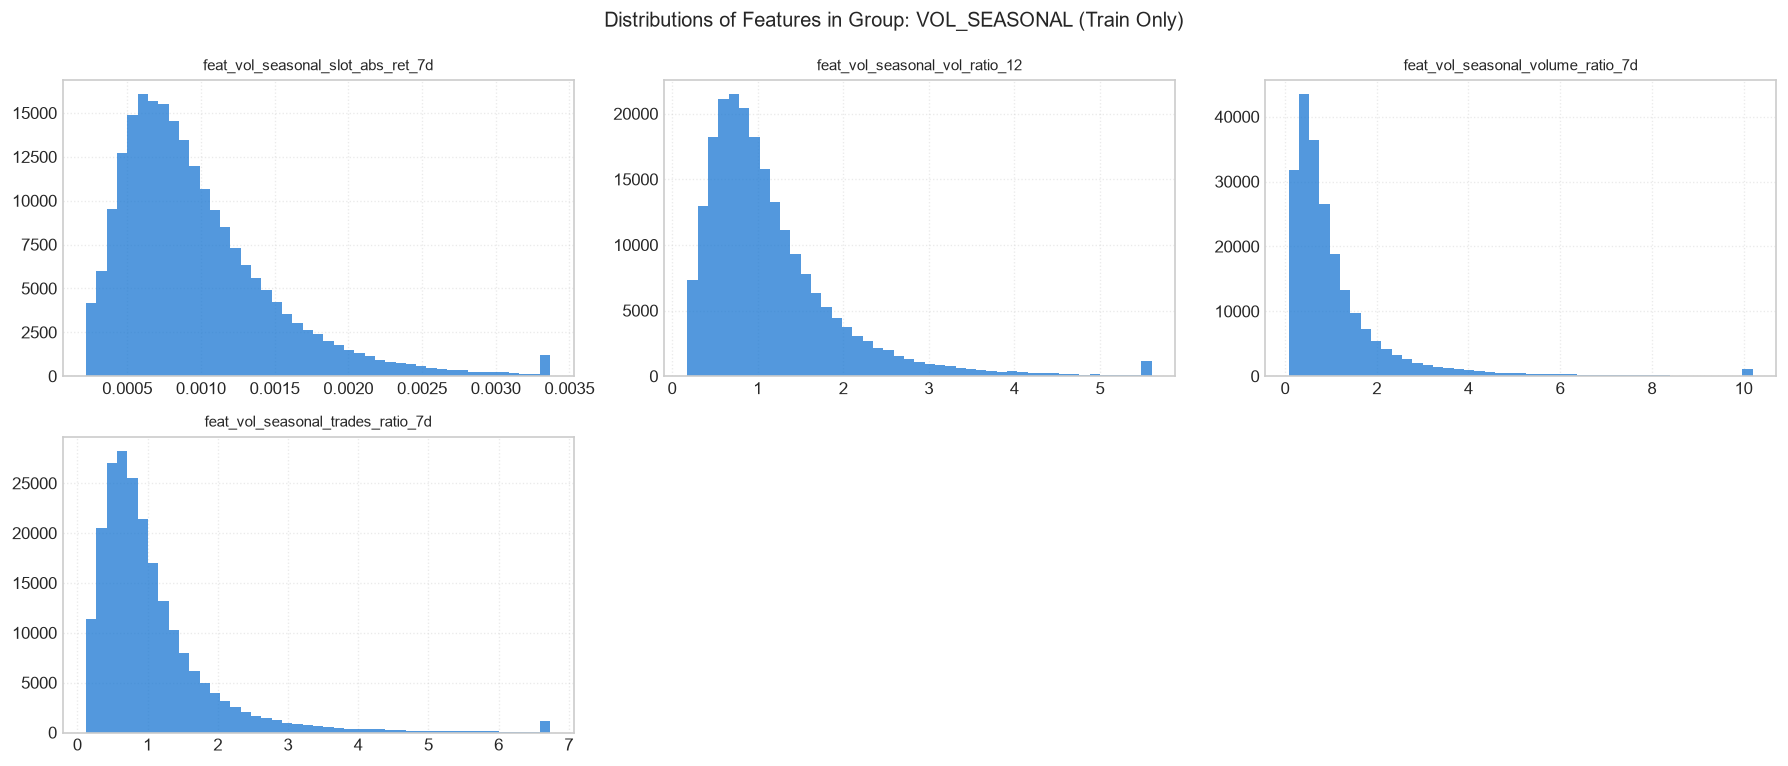

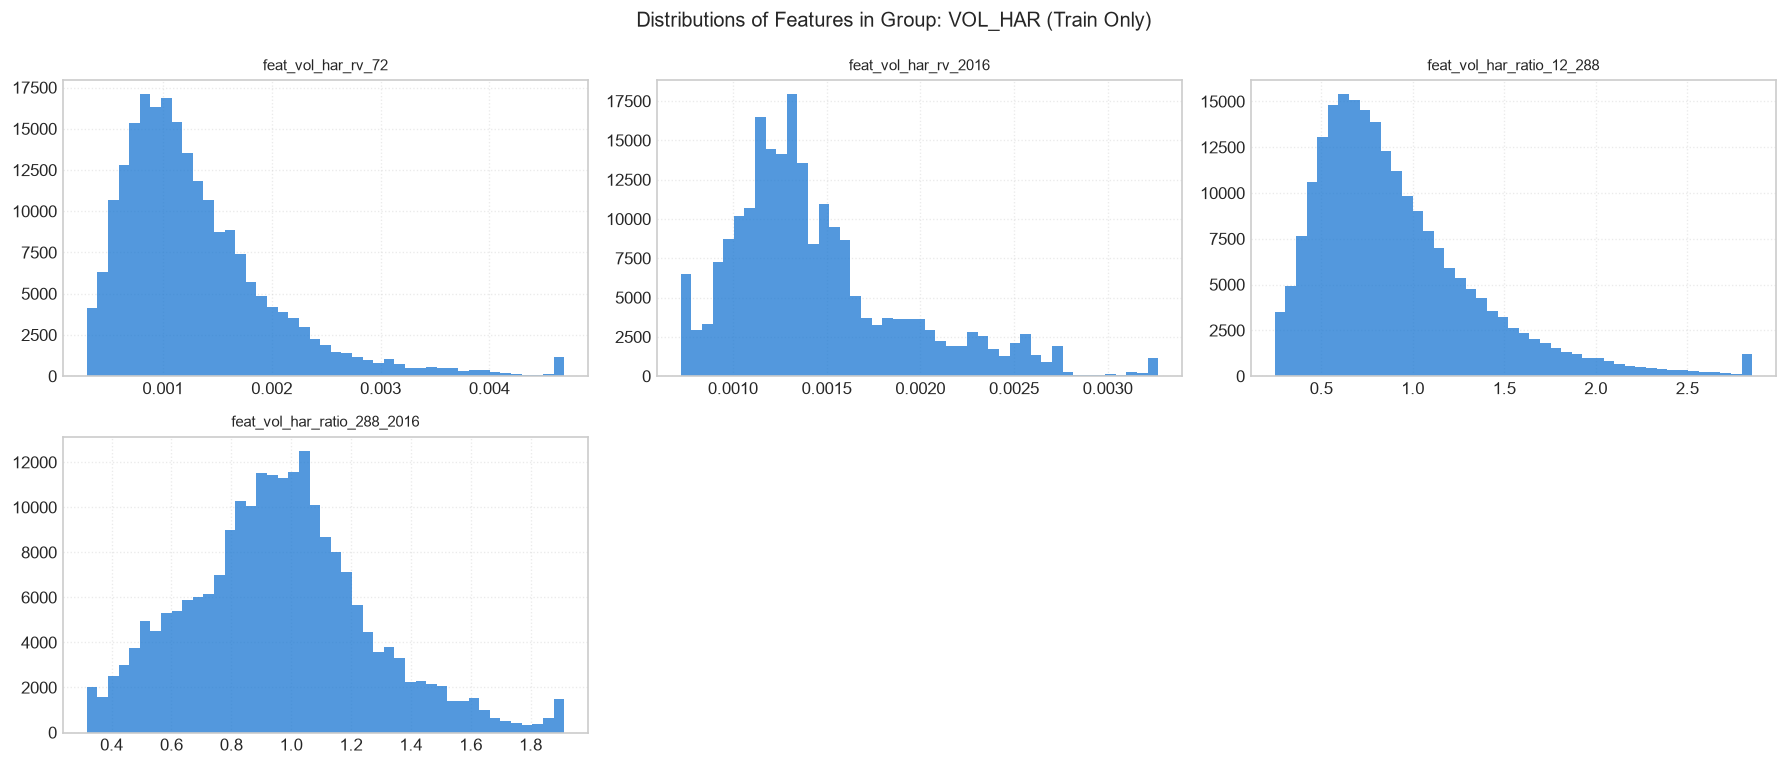

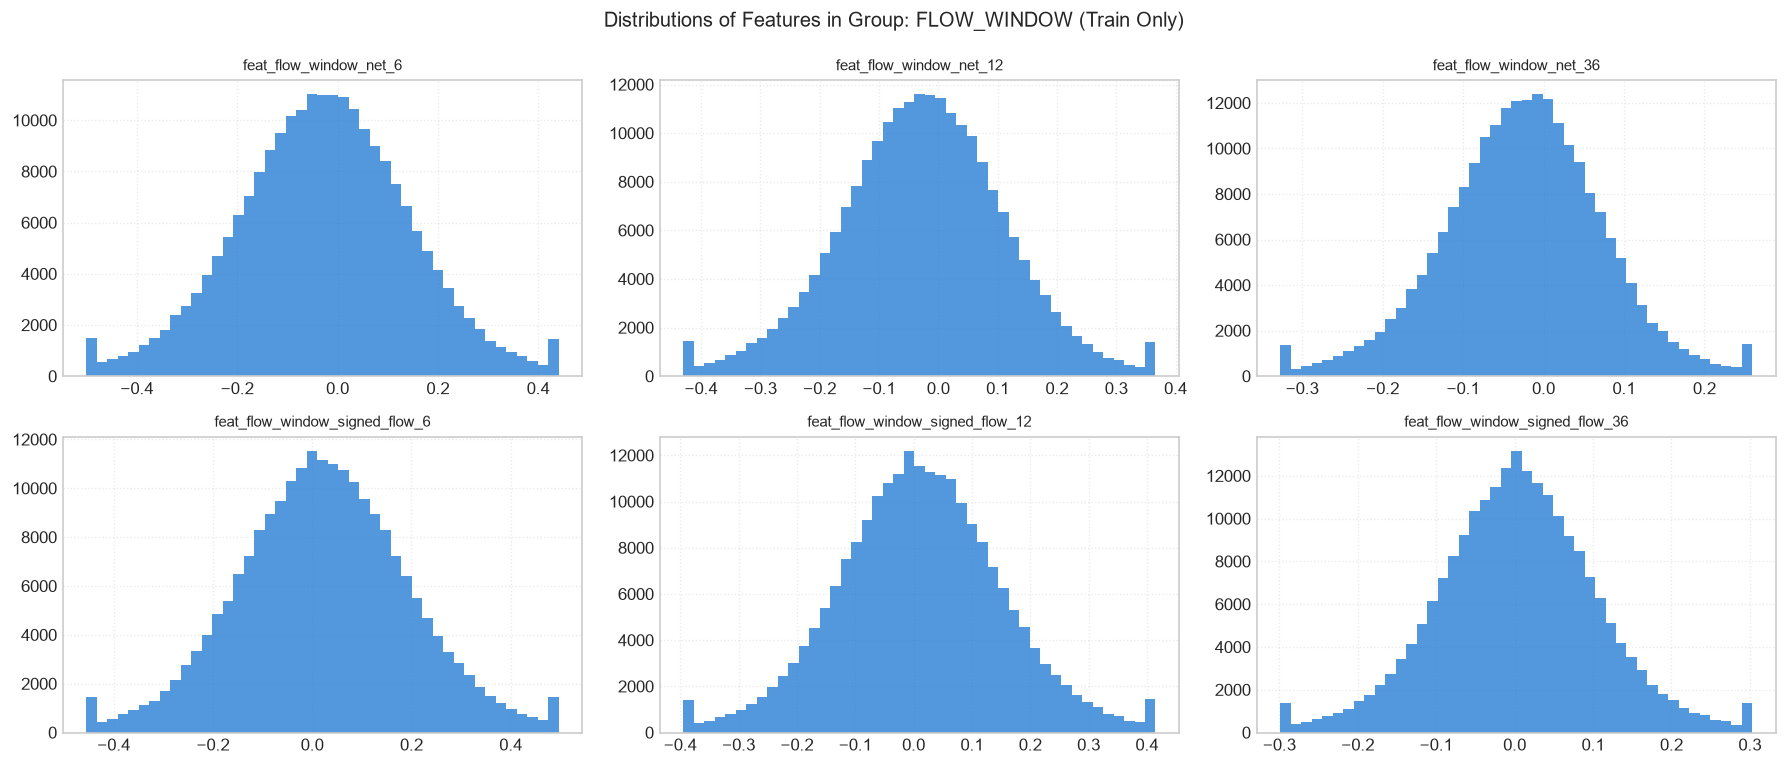

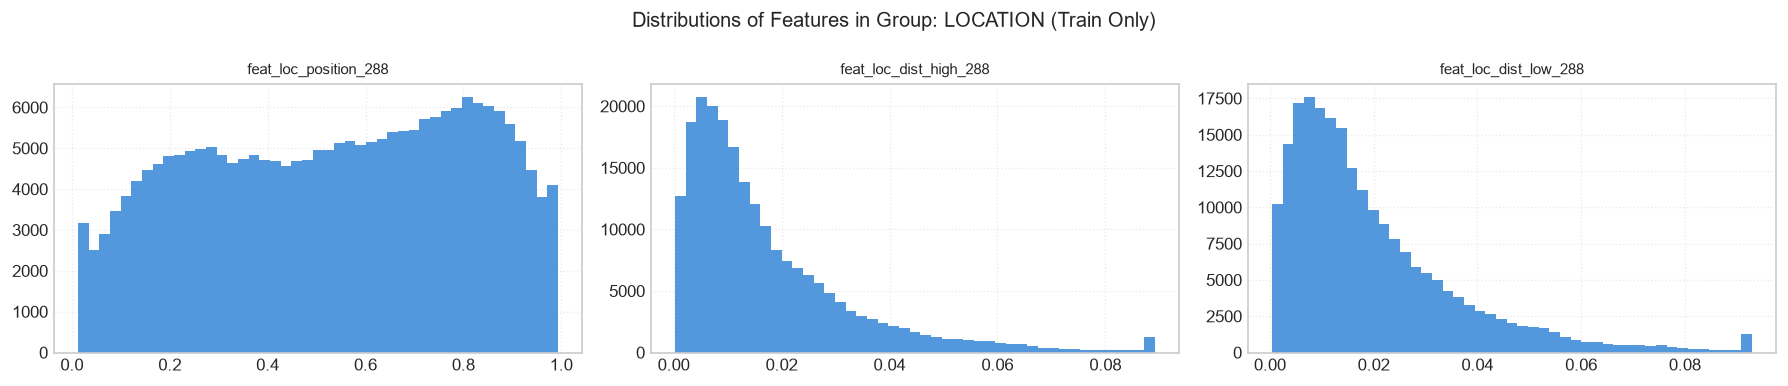

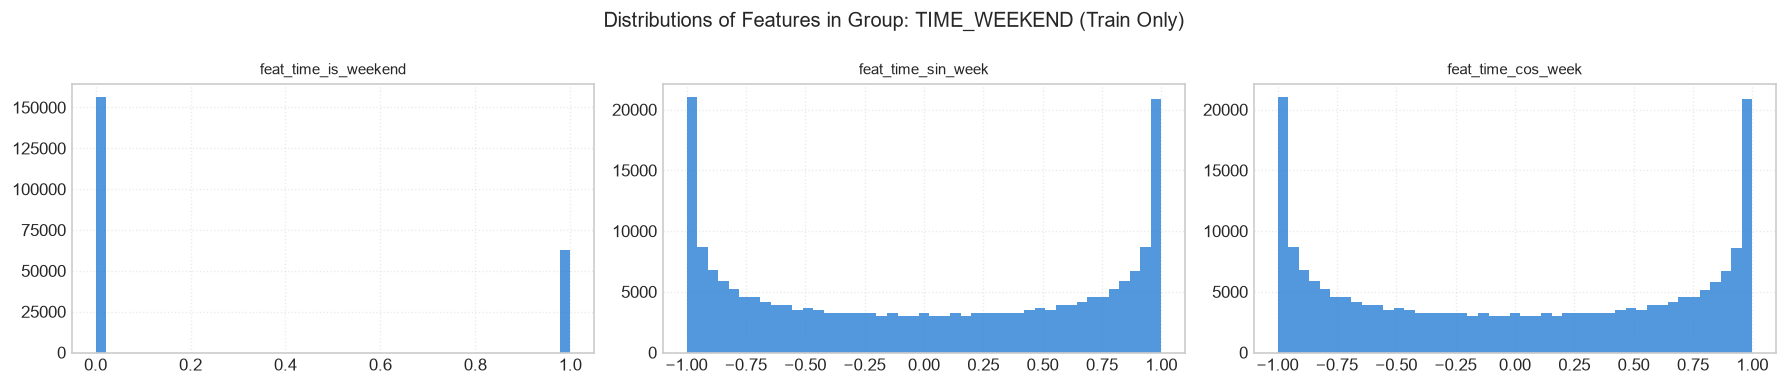

Interpretation: Visualized empirical distributions across all 15 feature groups; bounded oscillators (RSI, Bollinger %B) show expected uniform/bell profiles, while raw volatility and volume metrics exhibit heavy right-skewed tails.


In [4]:
# Plot distributions for each feature group
df_post_warmup = df_train.iloc[config.LOOKBACK_CANDLES:].copy()

for grp_name, grp_cols in FEATURE_GROUPS.items():
    sub_cols = [c for c in grp_cols if c in df_post_warmup.columns]
    if sub_cols:
        save_p = config.FIGURES_DIR / f"04_dist_{grp_name}.png"
        fig = plot_feature_group_histograms(
            df_post_warmup[sub_cols],
            group_name=grp_name,
            feature_cols=sub_cols,
            save_path=save_p,
        )
        plt.show()

print(f"Interpretation: Visualized empirical distributions across all {len(FEATURE_GROUPS)} feature groups; bounded oscillators (RSI, Bollinger %B) show expected uniform/bell profiles, while raw volatility and volume metrics exhibit heavy right-skewed tails.")


## Section 4: Correlation Structure & Multicollinearity (VIF)
Pearson and Spearman correlation matrices, hierarchical clustered heatmap of all 85 features, individual per-group correlation heatmaps, top correlated pairs, pairs exceeding $|	ext{corr}| > 0.90$, and Variance Inflation Factors (Ridge $\lambda=10^{-5}$ and Plain VIF).


2026-11-11 18:16:48 | INFO     | feat_eda | Computing Pearson and Spearman correlation matrices across 85 features...


2026-11-11 18:17:22 | INFO     | feat_eda | Correlations computed: 3570 pairs total, 62 pairs with |corr| > 0.90


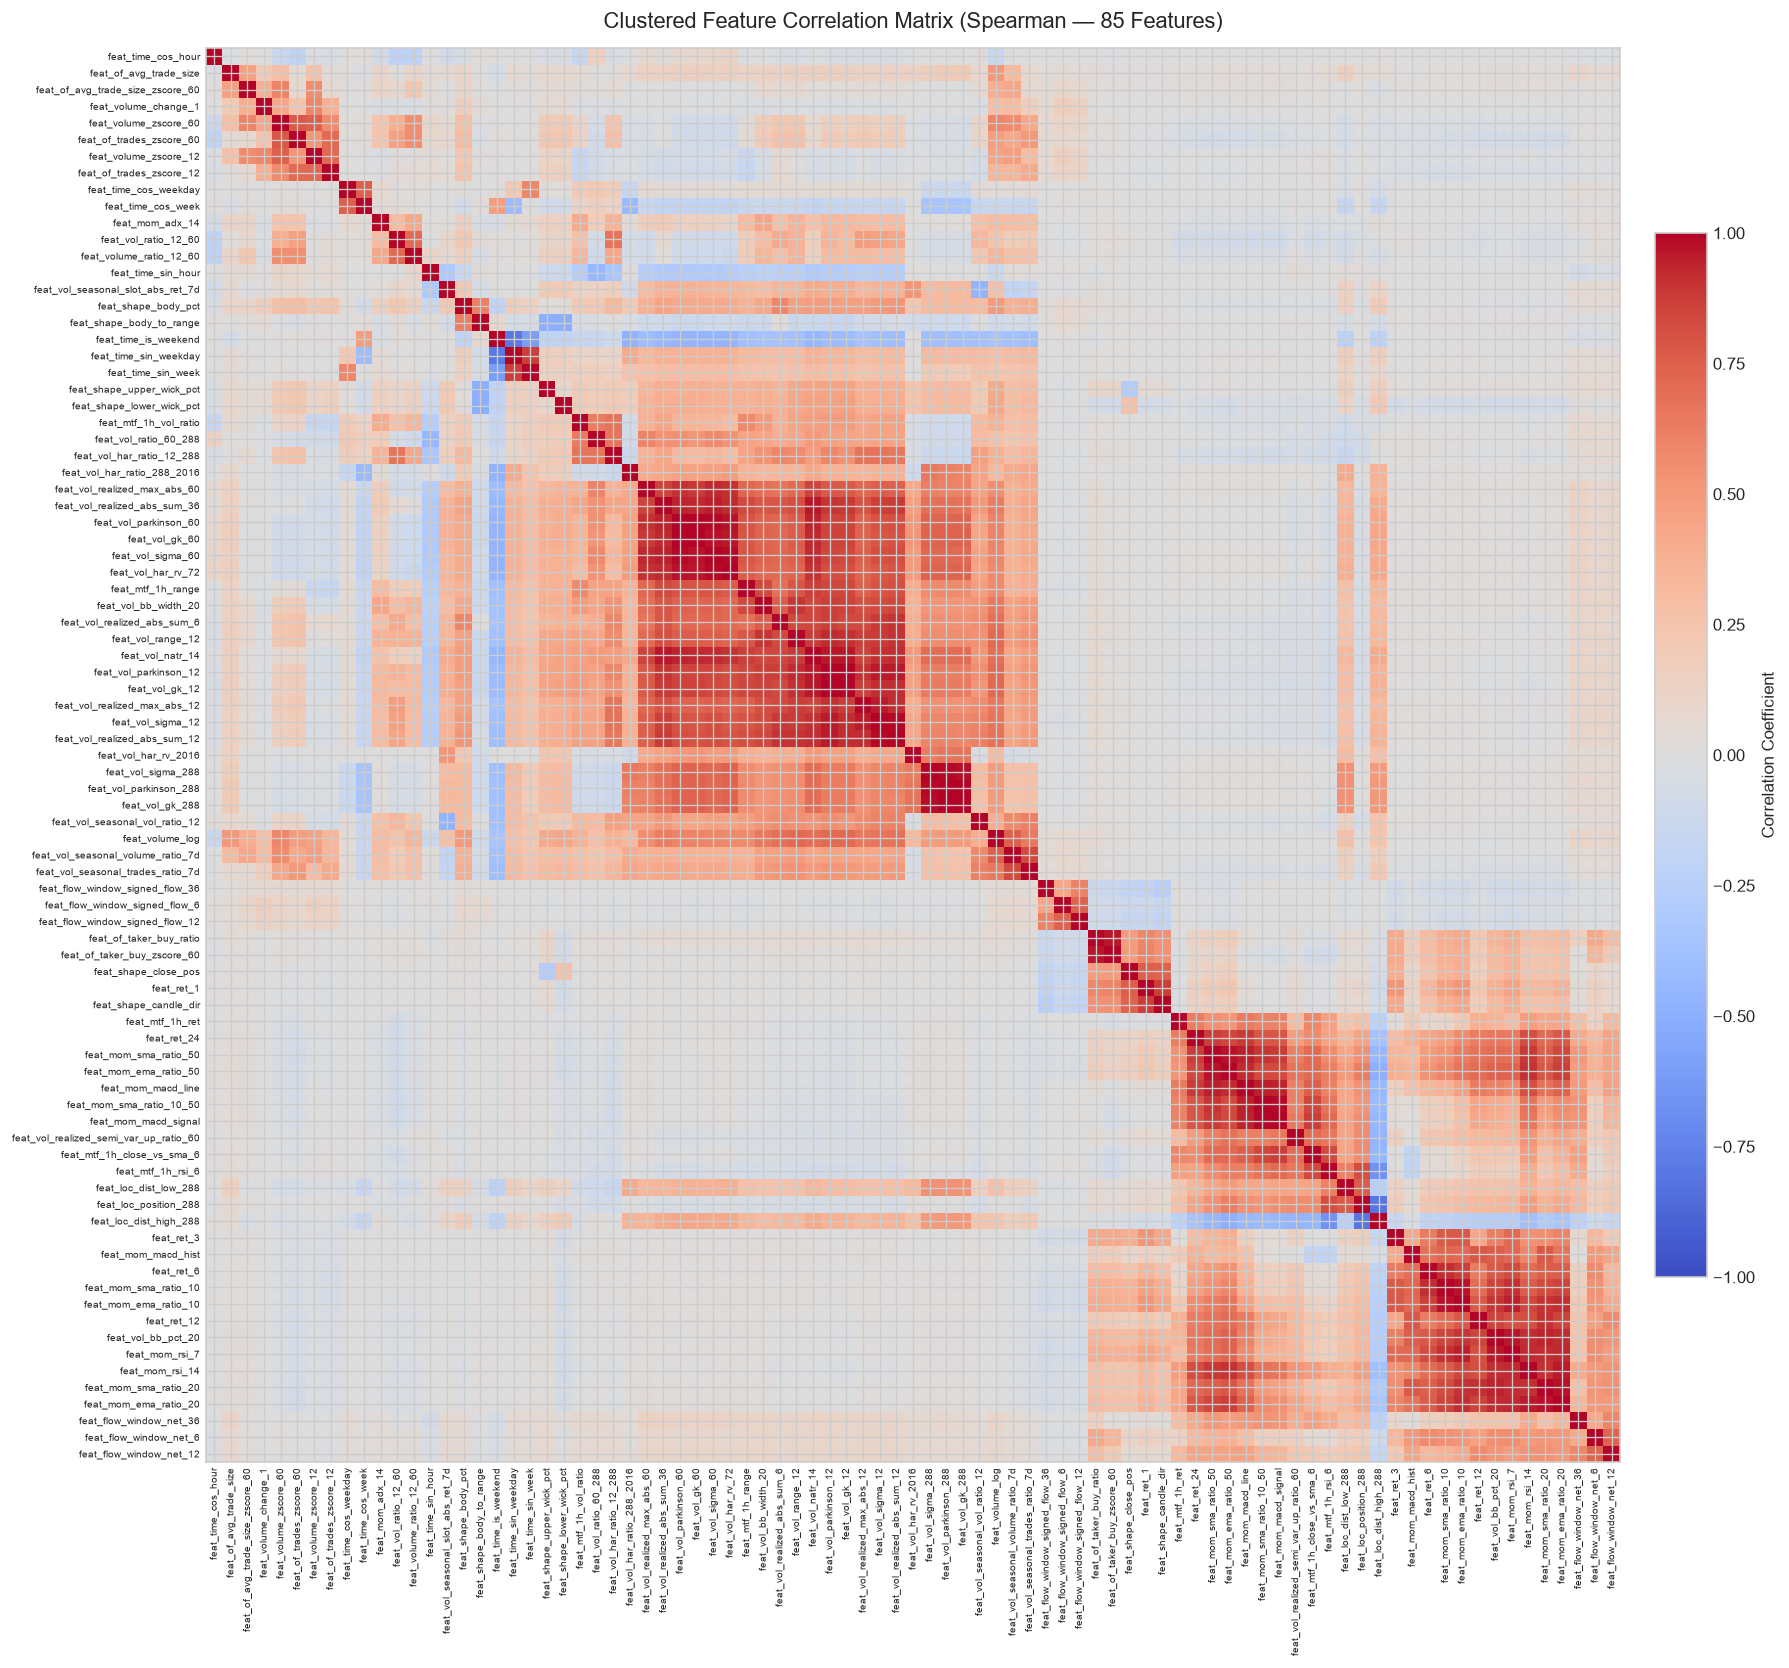

✓ Generated and saved 15 per-group correlation heatmaps (results/figures/04_corr_<group>.png).

=== TOP 10 CORRELATED FEATURE PAIRS (Spearman) ===


,feature_1,feature_2,spearman_corr,pearson_corr
0,feat_vol_parkinson_288,feat_vol_gk_288,0.998248,0.998133
1,feat_vol_parkinson_60,feat_vol_gk_60,0.997421,0.997009
2,feat_vol_parkinson_12,feat_vol_gk_12,0.992822,0.993466
3,feat_vol_sigma_288,feat_vol_parkinson_288,0.990875,0.988738
4,feat_mom_sma_ratio_10_50,feat_mom_macd_signal,0.989852,0.993780
5,feat_vol_sigma_60,feat_vol_parkinson_60,0.986196,0.982367
6,feat_vol_sigma_12,feat_vol_realized_abs_sum_12,0.984739,0.978961
7,feat_vol_sigma_60,feat_vol_har_rv_72,0.984564,0.978549
8,feat_vol_sigma_288,feat_vol_gk_288,0.981436,0.977798
9,feat_vol_parkinson_60,feat_vol_har_rv_72,0.976342,0.966256



Total feature pairs with |Spearman corr| > 0.90: 62 pairs


,feature_1,feature_2,spearman_corr
0,feat_vol_parkinson_288,feat_vol_gk_288,0.998248
1,feat_vol_parkinson_60,feat_vol_gk_60,0.997421
2,feat_vol_parkinson_12,feat_vol_gk_12,0.992822
3,feat_vol_sigma_288,feat_vol_parkinson_288,0.990875
4,feat_mom_sma_ratio_10_50,feat_mom_macd_signal,0.989852
5,feat_vol_sigma_60,feat_vol_parkinson_60,0.986196
6,feat_vol_sigma_12,feat_vol_realized_abs_sum_12,0.984739
7,feat_vol_sigma_60,feat_vol_har_rv_72,0.984564
8,feat_vol_sigma_288,feat_vol_gk_288,0.981436
9,feat_vol_parkinson_60,feat_vol_har_rv_72,0.976342



Raw Correlation Matrix Condition Number: 3.1626e+05
Smallest Eigenvalues: [6.20364224e-05 9.85366530e-05 6.64294438e-04 2.87702858e-03
 4.80454357e-03]

=== TOP 10 VARIANCE INFLATION FACTORS (Ridge lambda = 1e-5) ===


,feature,group,vif_ridge
0,feat_vol_parkinson_288,vol_range,8218.525936
1,feat_vol_parkinson_60,vol_range,6256.697861
2,feat_vol_gk_288,vol_range,4108.246663
3,feat_vol_gk_60,vol_range,3177.478821
4,feat_vol_parkinson_12,vol_range,995.415707
5,feat_vol_sigma_288,volatility,832.455625
6,feat_vol_sigma_60,volatility,672.716060
7,feat_vol_gk_12,vol_range,535.956791
8,feat_vol_sigma_12,volatility,155.894501
9,feat_mom_sma_ratio_10_50,momentum,146.358934



=== TOP 10 PLAIN VIFs (Identical duplicates and MACD identity excluded) ===


,feature,group,vif_plain
0,feat_vol_parkinson_288,vol_range,9482.899239
1,feat_vol_parkinson_60,vol_range,6978.842940
2,feat_vol_gk_288,vol_range,4737.582134
3,feat_vol_gk_60,vol_range,3541.556900
4,feat_vol_parkinson_12,vol_range,1014.192464
5,feat_vol_sigma_288,volatility,952.007747
6,feat_vol_sigma_60,volatility,738.398097
7,feat_vol_gk_12,vol_range,545.966161
8,feat_vol_sigma_12,volatility,156.765093
9,feat_mom_sma_ratio_10_50,momentum,146.610567



Interpretation: Condition number (3.16e+05) reflects exact linear identity (feat_mom_macd_hist = line - signal) and multi-horizon moving average collinearity. Ridge VIF conditions the full matrix (highest VIF is feat_vol_parkinson_288 at 8218.53), while Plain VIF isolates extreme collinearity within multi-horizon moving average ratios.


In [5]:
# Compute correlation matrices and pairs
corr_pearson, corr_spearman, df_top20_pairs, df_above_90 = compute_feature_correlations(
    df_train, warmup_candles=config.LOOKBACK_CANDLES
)

# Plot clustered correlation heatmap across all 85 features
fig_clustered = plot_feature_correlations_clustered(
    corr_spearman,
    title=f"Clustered Feature Correlation Matrix (Spearman — {len(feature_cols)} Features)",
    save_path=config.FIGURES_DIR / "04_corr_clustered.png",
)
plt.show()

# Plot per-group correlation heatmaps for all 15 groups
saved_grp_heatmaps = plot_feature_group_correlation_heatmaps(
    df_post_warmup, FEATURE_GROUPS, figures_dir=config.FIGURES_DIR
)
print(f"✓ Generated and saved {len(saved_grp_heatmaps)} per-group correlation heatmaps (results/figures/04_corr_<group>.png).")

print("\n=== TOP 10 CORRELATED FEATURE PAIRS (Spearman) ===")
display(df_top20_pairs.head(10)[["feature_1", "feature_2", "spearman_corr", "pearson_corr"]])

print(f"\nTotal feature pairs with |Spearman corr| > 0.90: {len(df_above_90)} pairs")
display(df_above_90.head(10)[["feature_1", "feature_2", "spearman_corr"]])

# Compute VIF
df_vif_ridge, df_vif_plain, cond_num, smallest_eigvals = compute_feature_vif(corr_spearman, regularization=1e-5)

print(f"\nRaw Correlation Matrix Condition Number: {cond_num:.4e}")
print(f"Smallest Eigenvalues: {smallest_eigvals}")

print("\n=== TOP 10 VARIANCE INFLATION FACTORS (Ridge lambda = 1e-5) ===")
display(df_vif_ridge.head(10))

print("\n=== TOP 10 PLAIN VIFs (Identical duplicates and MACD identity excluded) ===")
display(df_vif_plain.head(10))

top_vif_feat = df_vif_ridge.iloc[0]["feature"]
top_vif_val = df_vif_ridge.iloc[0]["vif_ridge"]
print(f"\nInterpretation: Condition number ({cond_num:.2e}) reflects exact linear identity (feat_mom_macd_hist = line - signal) and multi-horizon moving average collinearity. Ridge VIF conditions the full matrix (highest VIF is {top_vif_feat} at {top_vif_val:.2f}), while Plain VIF isolates extreme collinearity within multi-horizon moving average ratios.")


## Section 5: Size Side Analysis (`big_move_N` Setup D Worth-It Target)
Predictive capacity of each feature for identifying tradeable volatility expansion moves ($|\text{fwd\_ret}_N| > c = 0.23\%$). Single-feature ROC AUC, Cohen's d effect sizes, and group-level performance summaries.  
*Note: Results are described strictly in terms of ROC AUC and effect size, never as trading profit.*


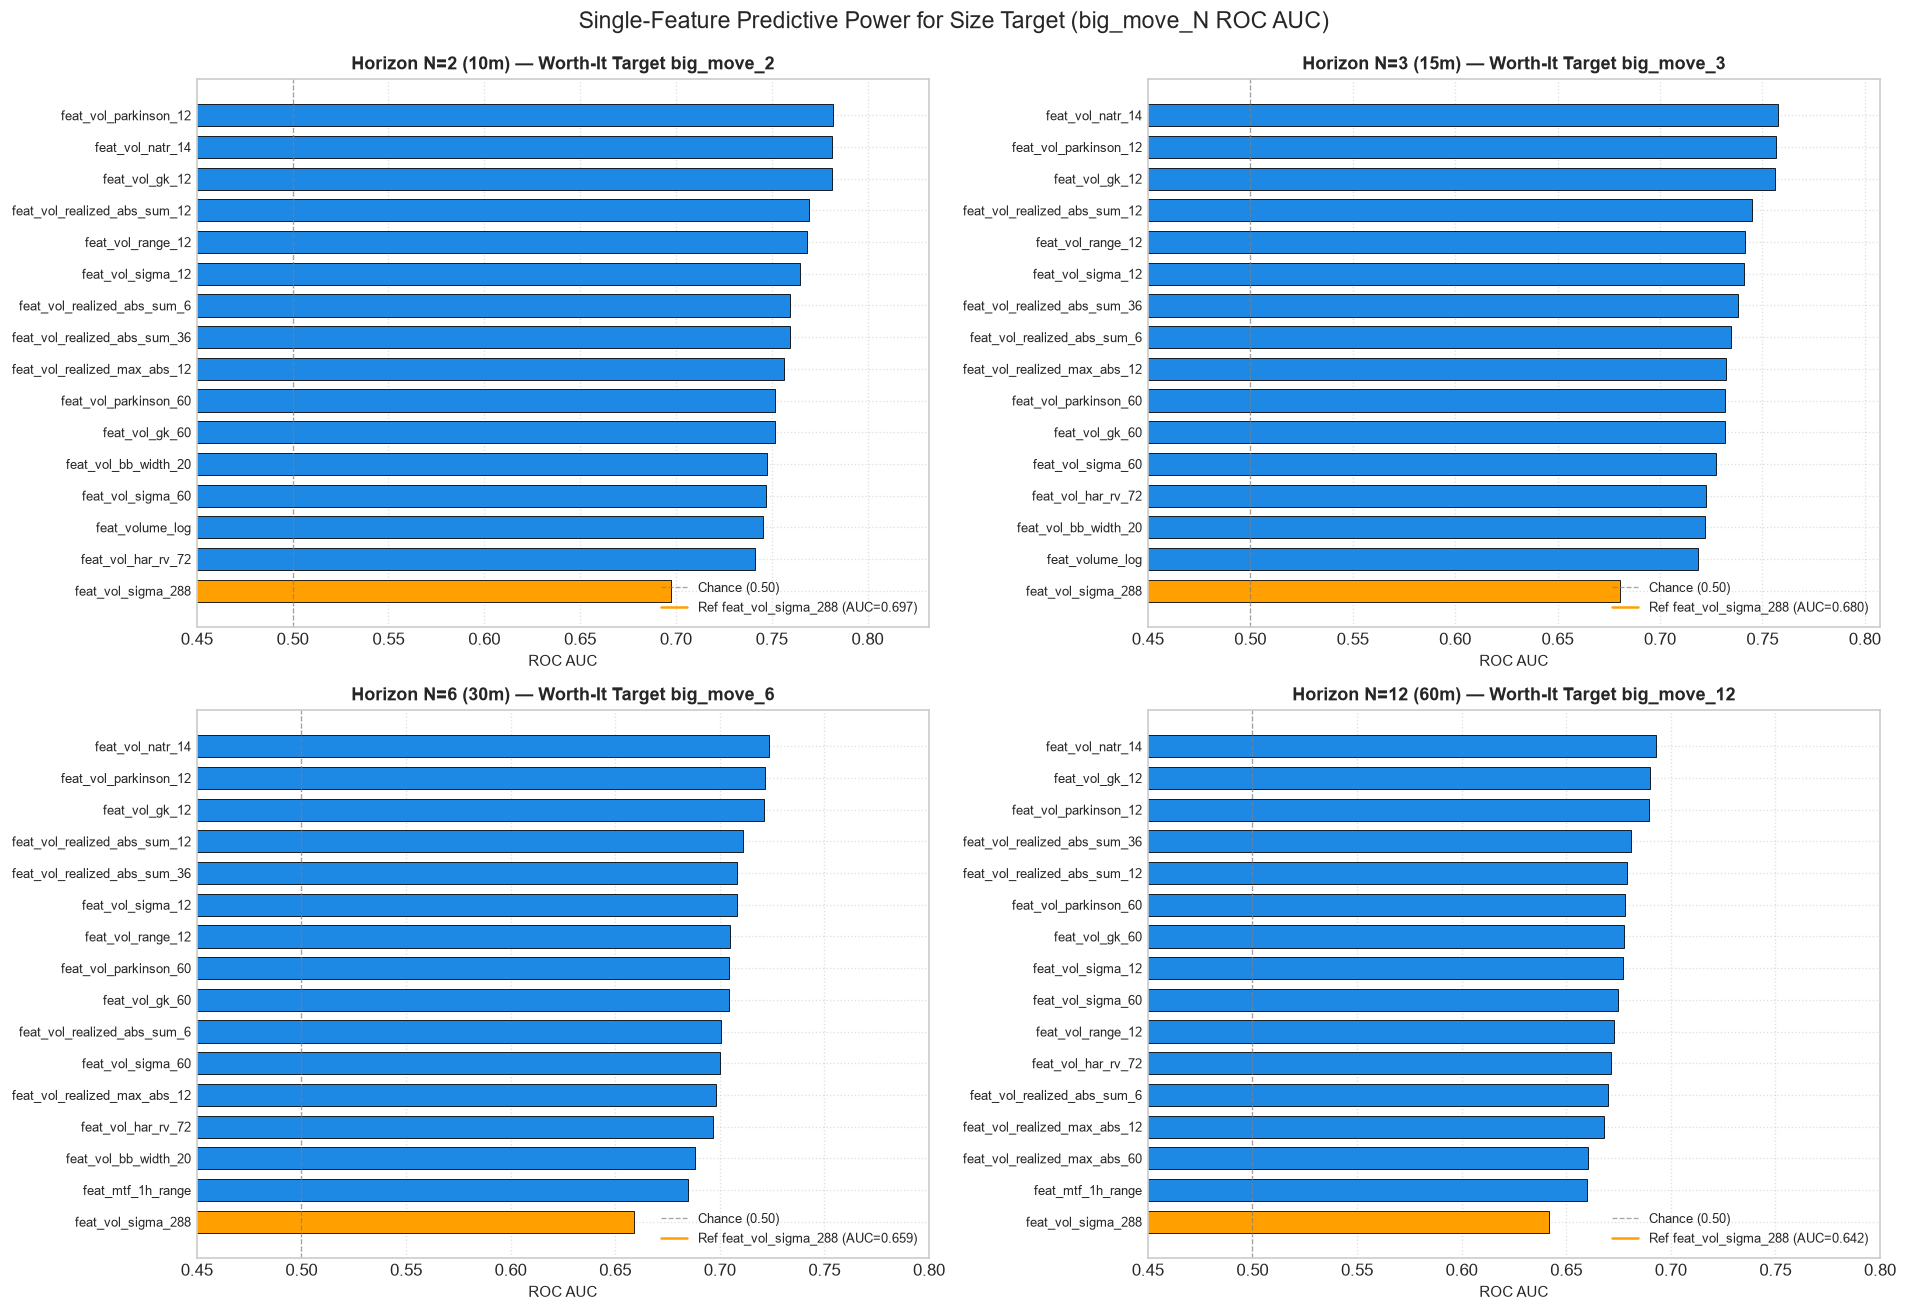

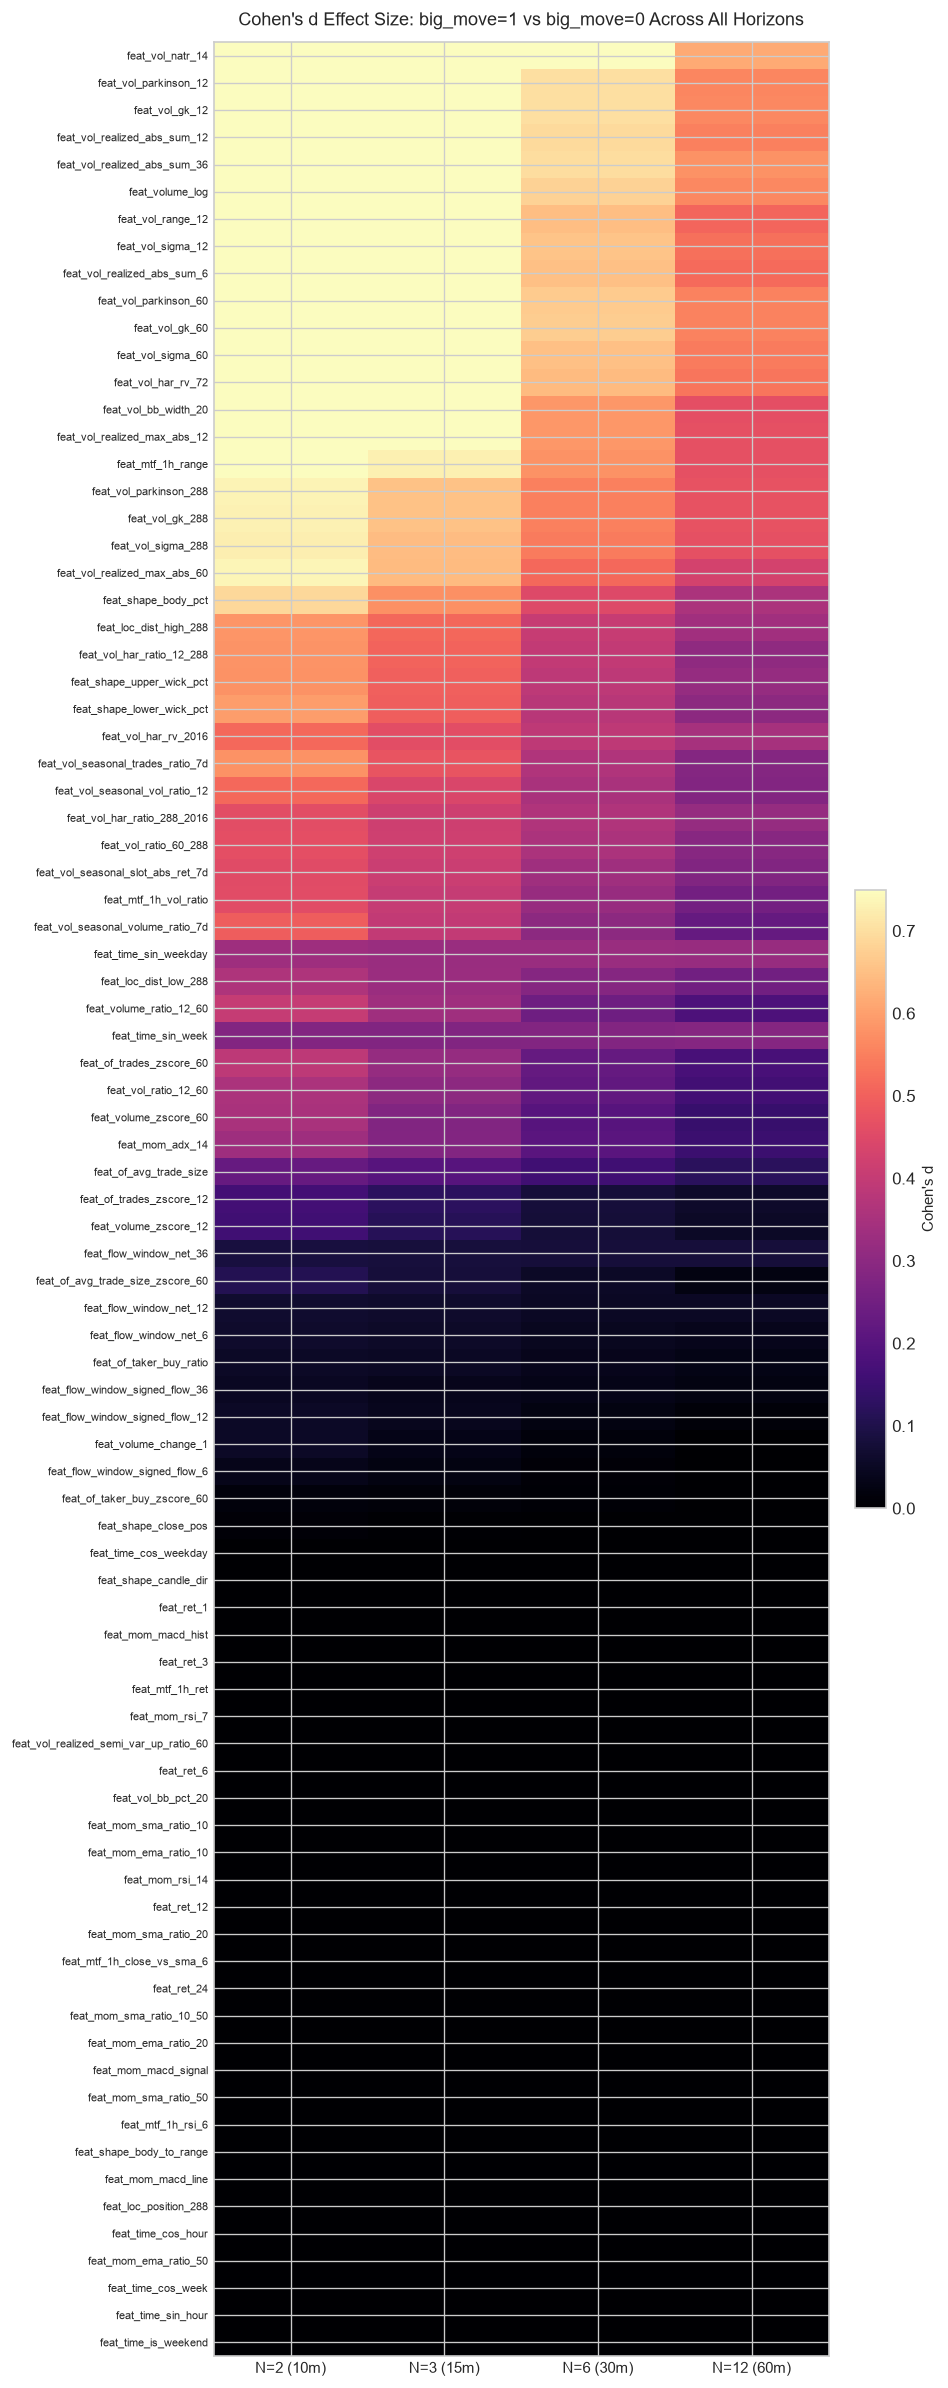

=== GROUP-LEVEL SIZE ROC AUC SUMMARY (Best & Median per Group) ===


,group,n_features,best_auc_2,median_auc_2,best_auc_3,median_auc_3,best_auc_6,median_auc_6,best_auc_12,median_auc_12
13,volatility,9,0.781500,0.746884,0.757415,0.722175,0.723674,0.688152,0.692796,0.659387
10,vol_range,6,0.782091,0.751735,0.756883,0.731707,0.721444,0.704289,0.689853,0.677872
11,vol_realized,6,0.769298,0.758030,0.744823,0.733356,0.711154,0.699389,0.680820,0.669022
9,vol_har,4,0.741474,0.649212,0.722285,0.634111,0.696519,0.613634,0.671388,0.596430
4,mtf_1h,5,0.732148,0.535373,0.712154,0.530056,0.684899,0.520818,0.659989,0.517687
14,volume,5,0.745594,0.590169,0.718794,0.573612,0.683470,0.552689,0.654706,0.539220
12,vol_seasonal,4,0.671289,0.651561,0.651805,0.634147,0.627998,0.615041,0.607947,0.595833
0,candle_shape,6,0.666469,0.583484,0.647540,0.577937,0.624804,0.566389,0.605346,0.559607
7,time,4,0.595877,0.567370,0.593316,0.559794,0.593035,0.549087,0.592811,0.540493
8,time_weekend,3,0.590809,0.583402,0.588537,0.582560,0.587385,0.582461,0.587102,0.584327



=== TOP 15 SINGLE FEATURES FOR SIZE PREDICTION (Horizon N=12 / 60m) ===


,feature,group,auc_2,auc_3,auc_6,auc_12
10,feat_vol_natr_14,volatility,0.781500,0.757415,0.723674,0.692796
56,feat_vol_gk_12,vol_range,0.781251,0.756316,0.721118,0.689853
53,feat_vol_parkinson_12,vol_range,0.782091,0.756883,0.721444,0.689415
61,feat_vol_realized_abs_sum_36,vol_realized,0.759384,0.738047,0.708250,0.680820
60,feat_vol_realized_abs_sum_12,vol_realized,0.769298,0.744823,0.711154,0.678936
54,feat_vol_parkinson_60,vol_range,0.751860,0.731804,0.704325,0.677930
57,feat_vol_gk_60,vol_range,0.751609,0.731610,0.704252,0.677813
7,feat_vol_sigma_12,volatility,0.765017,0.741105,0.708011,0.677202
6,feat_vol_sigma_60,volatility,0.746884,0.727198,0.700245,0.674646
13,feat_vol_range_12,volatility,0.768324,0.741337,0.704967,0.672620



Interpretation: Size prediction is strongly separable across all candidate horizons. The strongest single feature for N=12 is 'feat_vol_natr_14' (volatility) with ROC AUC = 0.6928, outperforming the reference baseline feat_vol_sigma_288 (AUC = 0.6419). Realized volatility and range groups achieve median AUCs > 0.65.


In [6]:
# Compute size side metrics
df_auc_size, df_cohen_size, df_group_size = compute_size_side_metrics(
    df_train, horizons=config.CANDIDATE_HORIZONS, warmup_candles=config.LOOKBACK_CANDLES
)

# Plot ranked ROC AUC bars per horizon
fig_auc_size = plot_size_auc_ranked_bars(
    df_auc_size,
    horizons=config.CANDIDATE_HORIZONS,
    top_k=15,
    save_path=config.FIGURES_DIR / "04_auc_big_move_bar.png",
)
plt.show()

# Plot Cohen's d heatmap
fig_cohen_size = plot_size_cohens_d_heatmap(
    df_cohen_size,
    save_path=config.FIGURES_DIR / "04_cohens_d_big_move_heatmap.png",
)
plt.show()

print("=== GROUP-LEVEL SIZE ROC AUC SUMMARY (Best & Median per Group) ===")
display(df_group_size.sort_values(by="best_auc_12", ascending=False))

print("\n=== TOP 15 SINGLE FEATURES FOR SIZE PREDICTION (Horizon N=12 / 60m) ===")
display(df_auc_size.sort_values(by="auc_12", ascending=False).head(15)[["feature", "group", "auc_2", "auc_3", "auc_6", "auc_12"]])

top_size_feat = df_auc_size.sort_values(by="auc_12", ascending=False).iloc[0]
ref_auc_12 = df_auc_size.loc[df_auc_size["feature"] == "feat_vol_sigma_288", "auc_12"].values[0]

print(f"\nInterpretation: Size prediction is strongly separable across all candidate horizons. The strongest single feature for N=12 is '{top_size_feat['feature']}' ({top_size_feat['group']}) with ROC AUC = {top_size_feat['auc_12']:.4f}, outperforming the reference baseline feat_vol_sigma_288 (AUC = {ref_auc_12:.4f}). Realized volatility and range groups achieve median AUCs > 0.65.")


## Section 6: Direction Side Analysis (`raw_sign_N`), Noise Bands & Quarterly Stability
Predictive capacity of each feature for future price direction. Single-feature ROC AUC against raw sign, lagged correlation decay, rolling 30-day stability, circular-shift noise band benchmark (500 random shifts $\ge 2018$ candles, Train post-warmup only), and quarterly stability across all 9 quarters.


2026-11-11 18:22:55 | INFO     | feat_eda | Precomputing rank matrix across 85 features for circular-shift noise band...


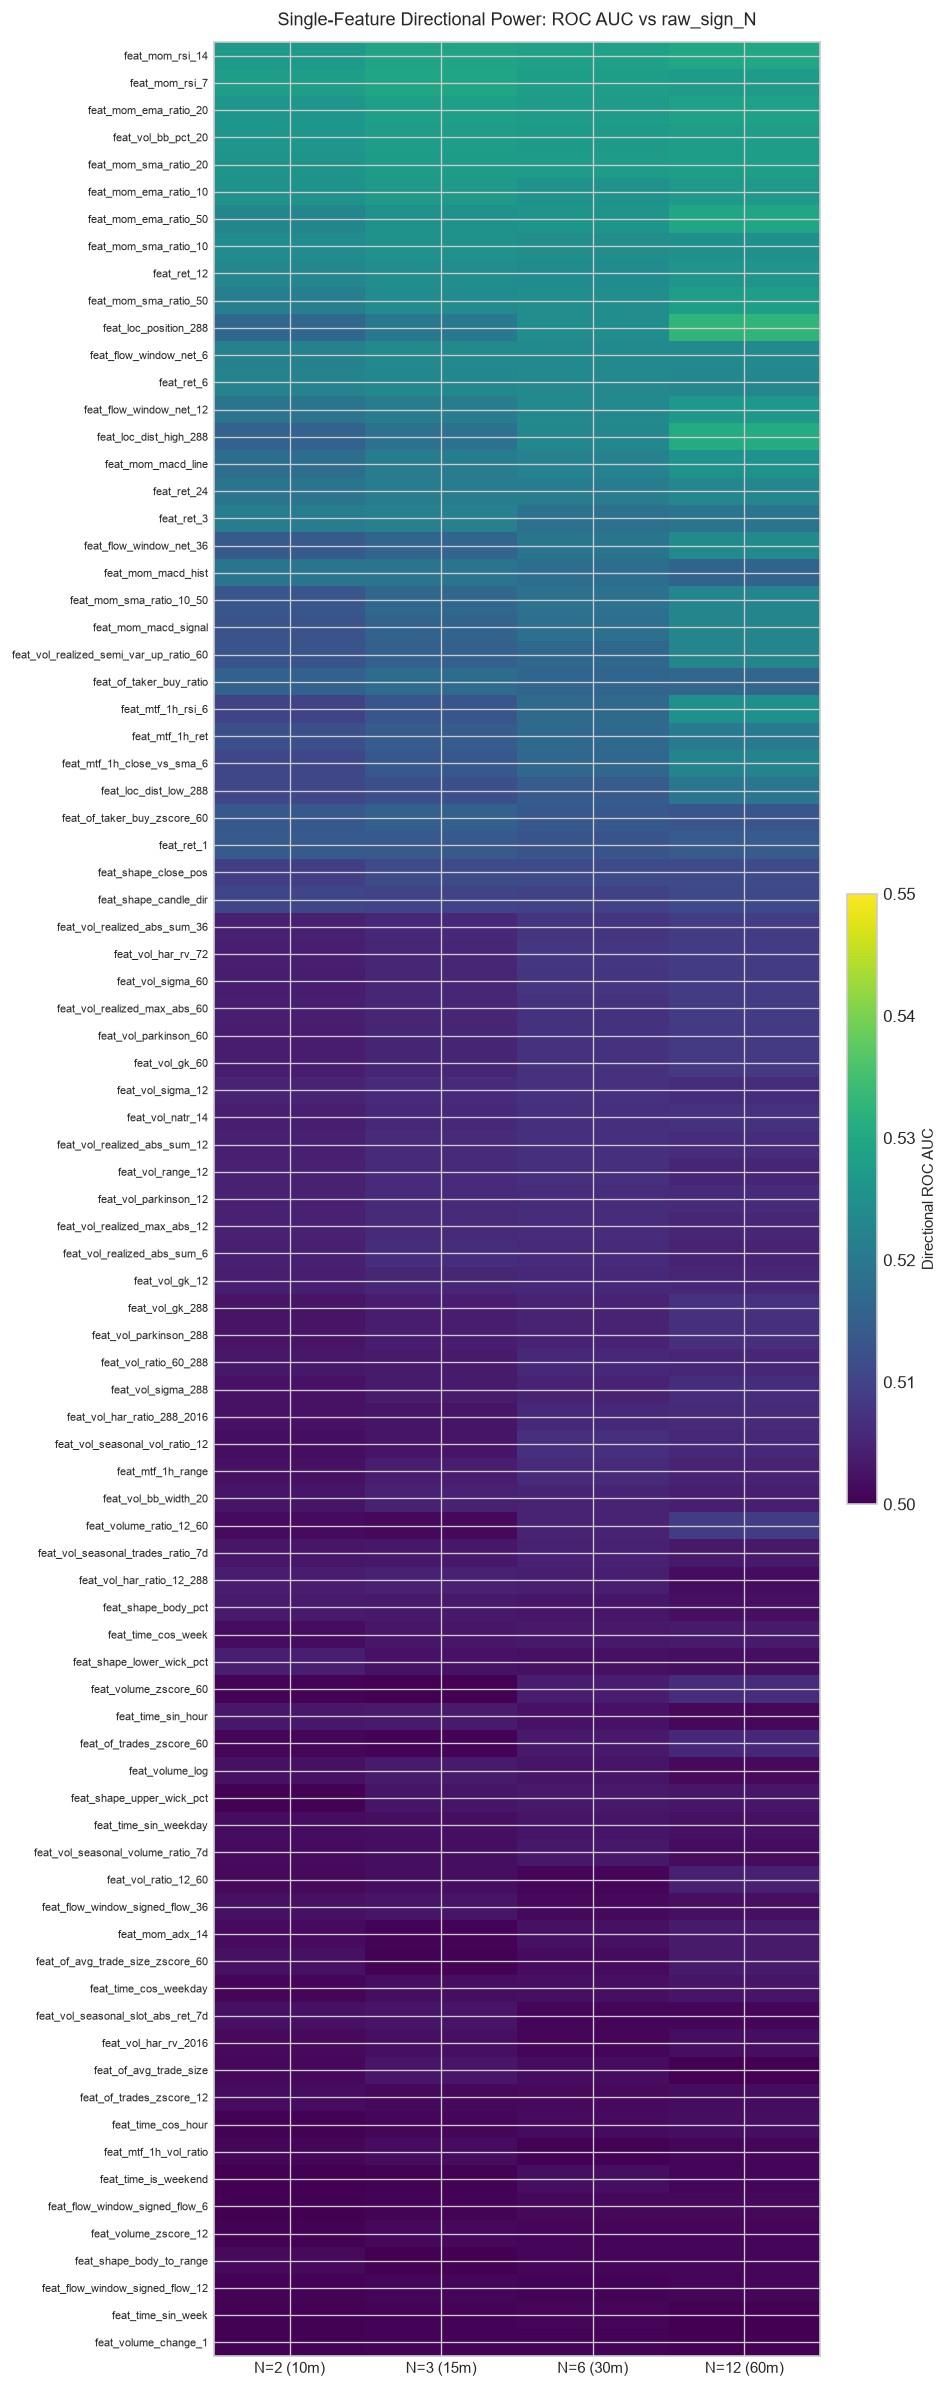

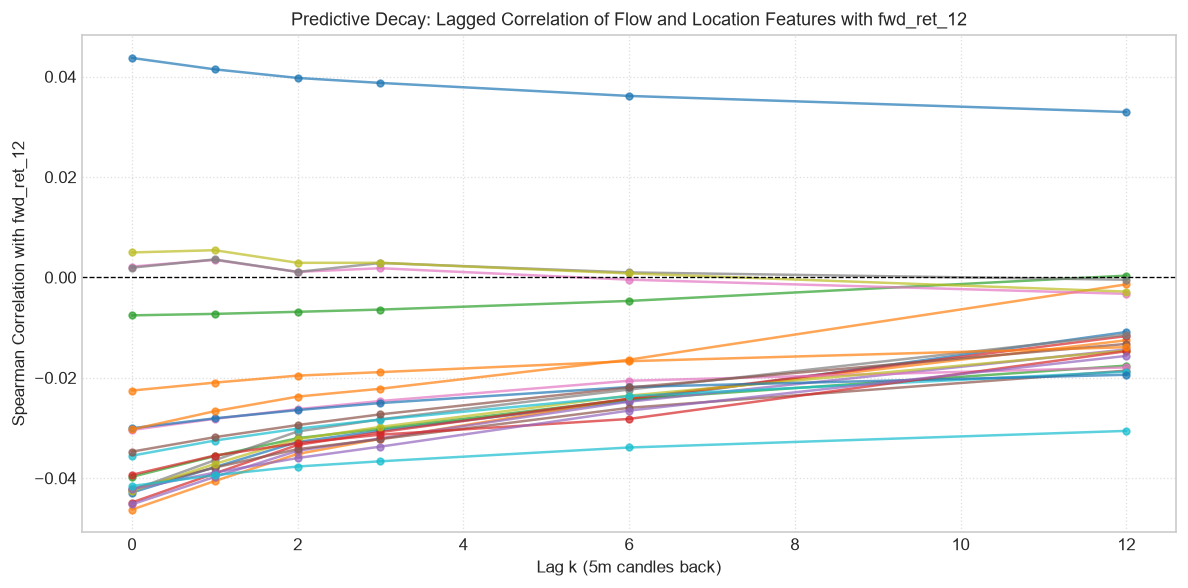

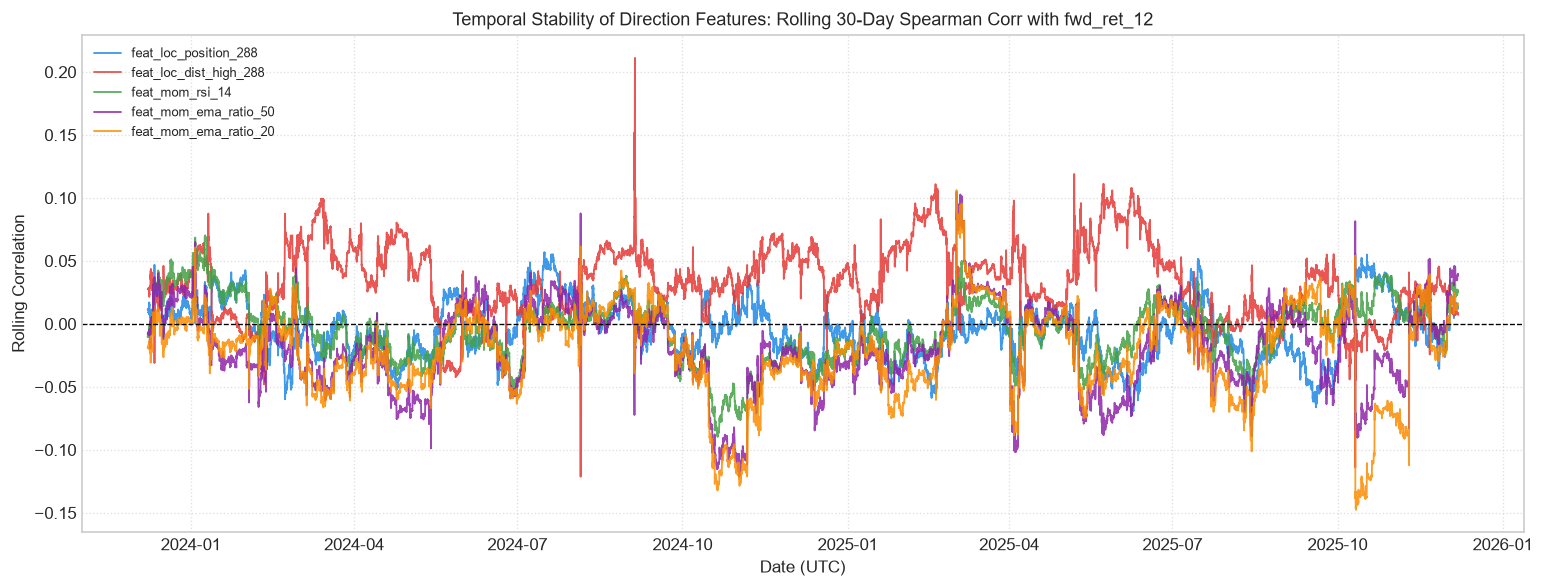

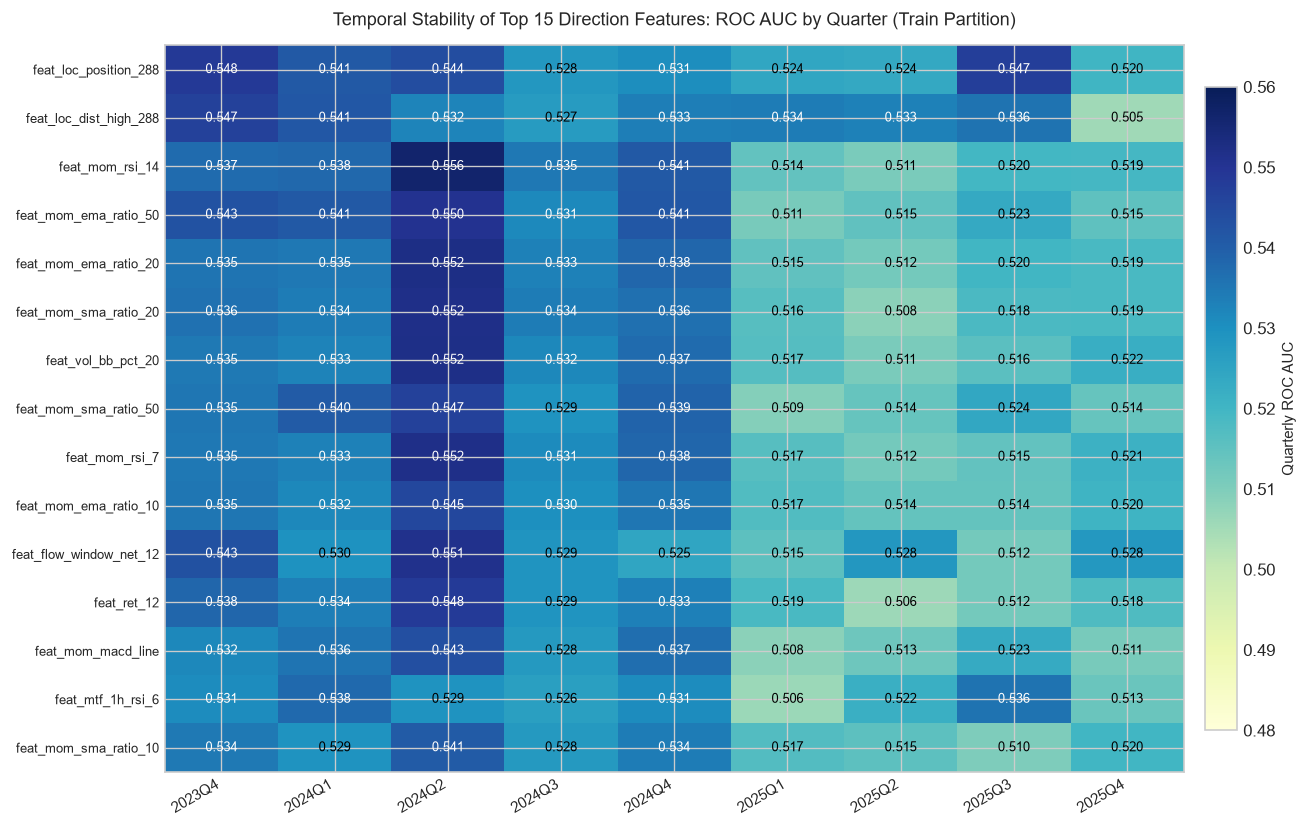

=== EMPIRICAL CIRCULAR-SHIFT NOISE BAND (500 SHIFTS >= 2018 CANDLES) ===


,side,horizon_N,circular_shift_max_95th,circular_shift_max_99th,circular_shift_feature_mean_95th,circular_shift_feature_mean_99th,iid_shuffle_95th_ignores_dependence
0,size,2,0.602217,0.605301,0.531016,0.542440,0.502324
1,size,3,0.591904,0.595500,0.529020,0.539993,0.502309
2,size,6,0.584067,0.589251,0.526582,0.536673,0.501655
3,size,12,0.584263,0.589339,0.525134,0.534257,0.502271
4,direction,2,0.504811,0.505168,0.502870,0.503640,0.502073
5,direction,3,0.505472,0.506498,0.503276,0.504185,0.503217
6,direction,6,0.507195,0.508213,0.504052,0.505238,0.501653
7,direction,12,0.509368,0.510888,0.505206,0.506608,0.502456



=== DIRECTION QUARTERLY STABILITY (Top 15 Features, 9 Quarters) ===


,feature,group,overall_auc_12,auc_2023Q4,auc_2024Q1,auc_2024Q2,auc_2024Q3,auc_2024Q4,auc_2025Q1,auc_2025Q2,auc_2025Q3,auc_2025Q4,share_same_sign_quarters
0,feat_loc_position_288,location,0.532710,0.548487,0.540952,0.543806,0.528325,0.530597,0.524078,0.523566,0.547375,0.520053,1.0
1,feat_loc_dist_high_288,location,0.530696,0.546589,0.541441,0.532466,0.527077,0.533469,0.533779,0.532915,0.535842,0.505392,1.0
2,feat_mom_rsi_14,momentum,0.529720,0.537231,0.538041,0.556466,0.534892,0.541024,0.514466,0.510726,0.519548,0.519151,1.0
3,feat_mom_ema_ratio_50,momentum,0.529657,0.542635,0.541037,0.550347,0.531310,0.541419,0.511089,0.514700,0.523163,0.515098,1.0
4,feat_mom_ema_ratio_20,momentum,0.528588,0.535342,0.534885,0.552286,0.532884,0.538296,0.514755,0.511725,0.519932,0.518515,1.0
5,feat_mom_sma_ratio_20,momentum,0.528123,0.536246,0.534055,0.551819,0.533758,0.536445,0.516459,0.508400,0.518290,0.518512,1.0
6,feat_vol_bb_pct_20,volatility,0.527797,0.534643,0.532735,0.552134,0.531732,0.537427,0.516801,0.510668,0.515738,0.522099,1.0
7,feat_mom_sma_ratio_50,momentum,0.527772,0.535277,0.540436,0.546631,0.529086,0.538786,0.509366,0.513992,0.523909,0.513902,1.0
8,feat_mom_rsi_7,momentum,0.527637,0.534827,0.532864,0.551569,0.531178,0.538130,0.516555,0.511820,0.514596,0.521227,1.0
9,feat_mom_ema_ratio_10,momentum,0.526891,0.535223,0.531787,0.545078,0.530131,0.535181,0.517349,0.514122,0.514323,0.520490,1.0



=== TOP 15 DIRECTION FEATURES (Horizon N=12 / 60m) ===


,feature,group,auc_2,auc_3,auc_6,auc_12,spearman_12,exceeds_99th_circular_max_12
79,feat_loc_position_288,location,0.516980,0.520135,0.524545,0.532710,-0.041562,True
80,feat_loc_dist_high_288,location,0.515814,0.518732,0.523214,0.530696,0.043729,True
28,feat_mom_rsi_14,momentum,0.527016,0.529179,0.528588,0.529720,-0.042561,True
25,feat_mom_ema_ratio_50,momentum,0.522865,0.525660,0.525815,0.529657,-0.042140,True
24,feat_mom_ema_ratio_20,momentum,0.526222,0.528181,0.527418,0.528588,-0.045232,True
21,feat_mom_sma_ratio_20,momentum,0.525790,0.527608,0.527344,0.528123,-0.046272,True
11,feat_vol_bb_pct_20,volatility,0.526187,0.527881,0.527336,0.527797,-0.042635,True
22,feat_mom_sma_ratio_50,momentum,0.521368,0.524194,0.524481,0.527772,-0.039736,True
27,feat_mom_rsi_7,momentum,0.527884,0.529343,0.527904,0.527637,-0.042406,True
23,feat_mom_ema_ratio_10,momentum,0.525675,0.526967,0.525773,0.526891,-0.044852,True



Caveat & Effective Sample Size:
  Valid train candles: 218,935
  Effective independent observations for N=12: n / 12 ≈ 18,244 blocks.
  Due to label horizon overlap, raw p-values are uncalibrated and are not quoted.

Interpretation: Directional predictive power is subtle compared to size. Top direction feature 'feat_loc_position_288' (location) achieves AUC = 0.5327. While clearing the i.i.d. noise floor (~0.502), 32 single features exceed the 99th percentile of the circular-shift maximum over 85 features (0.5109). Crucially, quarterly stability is high: top 15 direction features exhibit an average of 100.0% sign consistency across all 9 quarters from 2023Q4 to 2025Q4.


In [7]:
# Compute direction side metrics and circular-shift noise band
df_dir, df_lagged, df_noise, noise_band = compute_direction_side_metrics(
    df_train, horizons=config.CANDIDATE_HORIZONS, warmup_candles=config.LOOKBACK_CANDLES
)

# Plot direction metrics heatmap
fig_dir_heat = plot_direction_metrics_heatmap(
    df_dir,
    save_path=config.FIGURES_DIR / "04_direction_metrics_heatmap.png",
)
plt.show()

# Plot lagged flow and location decay
fig_lagged = plot_lagged_flow_loc(
    df_lagged,
    save_path=config.FIGURES_DIR / "04_lagged_flow_loc.png",
)
plt.show()

# Top 5 directional features by AUC at N=12
top_5_dir = df_dir.sort_values(by="auc_12", ascending=False).head(5)["feature"].tolist()
top_15_dir = df_dir.sort_values(by="auc_12", ascending=False).head(15)["feature"].tolist()

# Plot rolling 30-day correlation
fig_roll_dir = plot_rolling_direction_correlation(
    df_train.iloc[config.LOOKBACK_CANDLES:],
    top_features=top_5_dir,
    fwd_ret_col="fwd_ret_12",
    window_days=30,
    save_path=config.FIGURES_DIR / "04_rolling_corr_direction_5.png",
)
plt.show()

# Compute quarterly direction stability for top 15 features
df_q_stab = compute_direction_quarterly_stability(
    df_train, top_features=top_15_dir, warmup_candles=config.LOOKBACK_CANDLES
)

# Plot quarterly direction stability heatmap
fig_q_stab = plot_direction_quarterly_stability(
    df_q_stab,
    save_path=config.FIGURES_DIR / "04_direction_quarterly_stability.png",
)
plt.show()

print("=== EMPIRICAL CIRCULAR-SHIFT NOISE BAND (500 SHIFTS >= 2018 CANDLES) ===")
display(df_noise)

print("\n=== DIRECTION QUARTERLY STABILITY (Top 15 Features, 9 Quarters) ===")
display(df_q_stab)

print("\n=== TOP 15 DIRECTION FEATURES (Horizon N=12 / 60m) ===")
display(df_dir.sort_values(by="auc_12", ascending=False).head(15)[["feature", "group", "auc_2", "auc_3", "auc_6", "auc_12", "spearman_12", "exceeds_99th_circular_max_12"]])

top_dir_feat = df_dir.sort_values(by="auc_12", ascending=False).iloc[0]
dir_noise_max_99 = noise_band["direction_12_max_99th"]
dir_noise_max_95 = noise_band["direction_12_max_95th"]
n_exceed_99 = int(df_dir["exceeds_99th_circular_max_12"].sum())
mean_sign_consistency = df_q_stab["share_same_sign_quarters"].mean() * 100

# Effective sample size calculation
n_valid = len(df_train) - config.LOOKBACK_CANDLES
n_eff_12 = int(n_valid / 12)
print(f"\nCaveat & Effective Sample Size:")
print(f"  Valid train candles: {n_valid:,}")
print(f"  Effective independent observations for N=12: n / 12 ≈ {n_eff_12:,} blocks.")
print(f"  Due to label horizon overlap, raw p-values are uncalibrated and are not quoted.")

print(f"\nInterpretation: Directional predictive power is subtle compared to size. Top direction feature '{top_dir_feat['feature']}' ({top_dir_feat['group']}) achieves AUC = {top_dir_feat['auc_12']:.4f}. While clearing the i.i.d. noise floor (~0.502), {n_exceed_99} single features exceed the 99th percentile of the circular-shift maximum over 85 features ({dir_noise_max_99:.4f}). Crucially, quarterly stability is high: top 15 direction features exhibit an average of {mean_sign_consistency:.1f}% sign consistency across all 9 quarters from 2023Q4 to 2025Q4.")


## Section 7: Contextual Behavior & De-Seasoning Verification
Interaction of features with diurnal (hour of day UTC), day-of-week, and macro volatility tercile regimes. Verification that seasonal ratios eliminate the 24-hour cycle via Autocorrelation Function (ACF) decay.


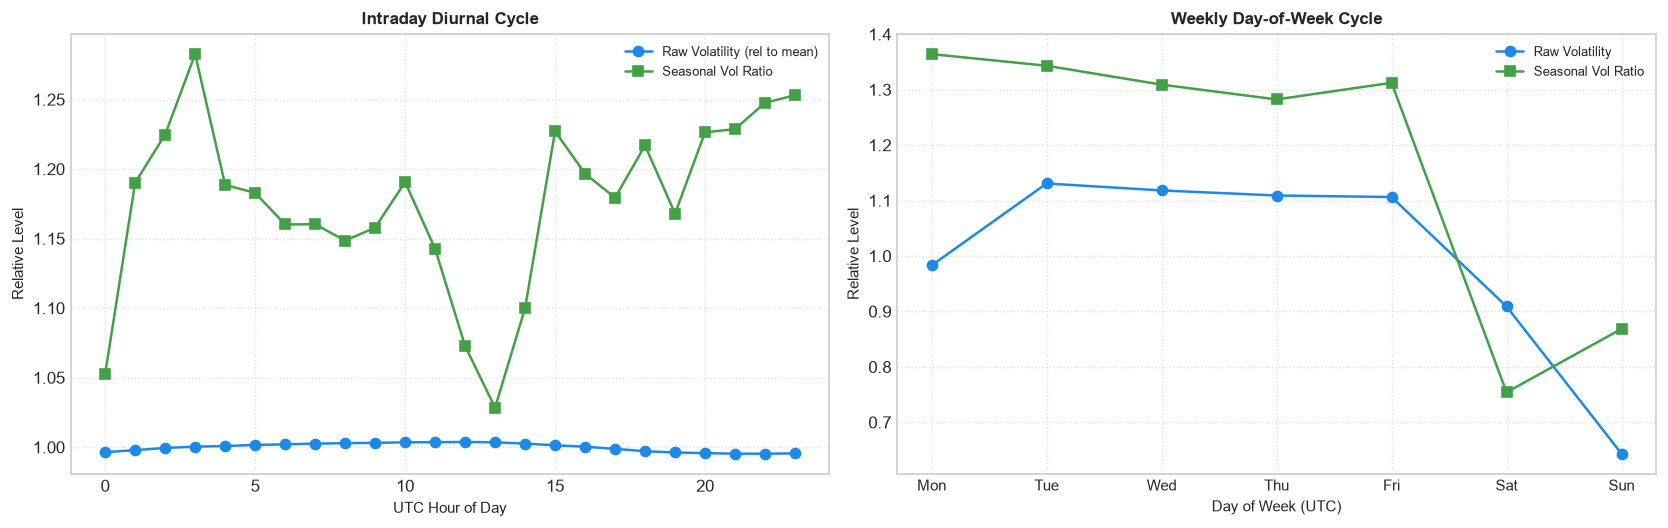

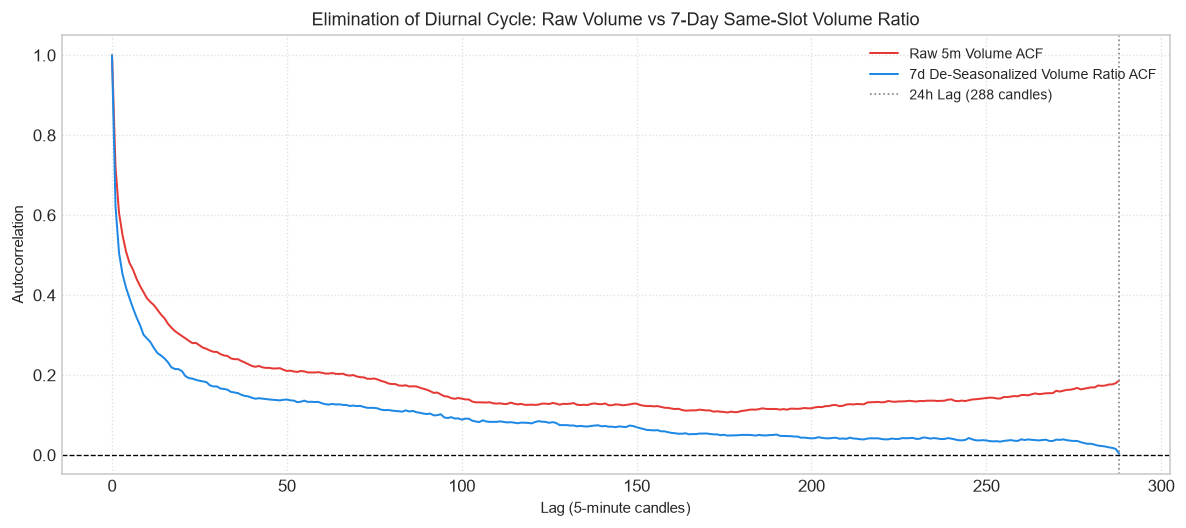

=== CONTEXT BY VOLATILITY TERCILE ===


,feat_vol_sigma_288,feat_vol_gk_60,feat_vol_seasonal_vol_ratio_12,feat_volume_log,feat_vol_seasonal_volume_ratio_7d,feat_flow_window_net_12,feat_of_taker_buy_ratio
feat_vol_sigma_288,,,,,,,
Low Volatility,0.000817,0.000693,0.936940,3.652104,0.901779,-0.038191,0.478849
Medium Volatility,0.001273,0.001104,1.139673,4.175304,1.116208,-0.027933,0.484073
High Volatility,0.002064,0.001813,1.451773,4.649260,1.497521,-0.017152,0.490738



Diurnal ACF at Lag 288 (24 hours):
  Raw 5m Volume ACF:            0.1868 (prominent diurnal peak)
  7d De-seasonalized Ratio ACF: 0.0033 (eliminated diurnal cycle)

Interpretation: De-seasonalized volume and trade ratios successfully eliminate the diurnal 24-hour cycle (ACF at lag 288 drops from 0.187 to 0.003), providing pure anomaly signals independent of time-of-day activity.


In [8]:
# Compute context profiles and ACF
by_hour, by_dow, by_tercile, df_acf = compute_context_analysis(
    df_train, warmup_candles=config.LOOKBACK_CANDLES
)

# Plot context profiles
fig_context = plot_context_profiles(
    by_hour,
    by_dow,
    save_path=config.FIGURES_DIR / "04_context_profiles.png",
)
plt.show()

# Plot ACF de-seasoning
fig_acf = plot_acf_deseasoning(
    df_acf,
    save_path=config.FIGURES_DIR / "04_acf_deseasoning.png",
)
plt.show()

print("=== CONTEXT BY VOLATILITY TERCILE ===")
display(by_tercile)

# Check diurnal peak reduction at lag 288 (24h)
raw_acf_288 = df_acf.loc[df_acf["lag"] == 288, "acf_raw_volume"].values[0]
seas_acf_288 = df_acf.loc[df_acf["lag"] == 288, "acf_deseasoned_volume"].values[0]

print(f"\nDiurnal ACF at Lag 288 (24 hours):")
print(f"  Raw 5m Volume ACF:            {raw_acf_288:.4f} (prominent diurnal peak)")
print(f"  7d De-seasonalized Ratio ACF: {seas_acf_288:.4f} (eliminated diurnal cycle)")
print(f"\nInterpretation: De-seasonalized volume and trade ratios successfully eliminate the diurnal 24-hour cycle (ACF at lag 288 drops from {raw_acf_288:.3f} to {seas_acf_288:.3f}), providing pure anomaly signals independent of time-of-day activity.")


## Section 8: Stability & Quarterly Regime Drift
Quarterly means and standard deviations across the fixed training window (2023 Q4 to 2025 Q4). Features exhibiting quarterly mean movement $> 0.5$ overall standard deviations are flagged for monitoring.


In [9]:
# Compute quarterly drift
df_drift = compute_quarterly_drift(
    df_train, warmup_candles=config.LOOKBACK_CANDLES, drift_threshold_std=0.5
)

drifting_feats = df_drift[df_drift["has_temporal_drift"]]
print(f"=== QUARTERLY DRIFT MONITORING ({len(drifting_feats)} / {len(df_drift)} Features Flagged) ===")
print("Top 10 Most Drifting Features:")
display(df_drift.head(10)[["feature", "group", "overall_mean", "overall_std", "max_quarterly_drift_std", "has_temporal_drift"]])

print(f"\nInterpretation: {len(drifting_feats)} features drift by more than 0.5 std across the 2023-2025 regimes. Volatility and long-window moving average ratios show substantial macro shifts between bear consolidation (Q4 2023) and bull expansion (Q1 2024), underscoring the necessity of rolling walk-forward evaluation in Step 5.")


=== QUARTERLY DRIFT MONITORING (15 / 85 Features Flagged) ===
Top 10 Most Drifting Features:


,feature,group,overall_mean,overall_std,max_quarterly_drift_std,has_temporal_drift
0,feat_of_avg_trade_size,order_flow,0.011734,0.009240,1.465400,True
1,feat_vol_har_rv_2016,vol_har,0.001453,0.000477,1.104080,True
2,feat_vol_gk_288,vol_range,0.001279,0.000656,0.787988,True
3,feat_vol_parkinson_288,vol_range,0.001311,0.000653,0.779937,True
4,feat_vol_sigma_288,volatility,0.001384,0.000654,0.752499,True
5,feat_volume_log,volume,4.158891,0.937004,0.650180,True
6,feat_vol_seasonal_slot_abs_ret_7d,vol_seasonal,0.000980,0.000556,0.619442,True
7,feat_vol_gk_60,vol_range,0.001204,0.000786,0.615822,True
8,feat_vol_natr_14,volatility,0.001780,0.001146,0.608977,True
9,feat_vol_parkinson_60,vol_range,0.001237,0.000784,0.607565,True



Interpretation: 15 features drift by more than 0.5 std across the 2023-2025 regimes. Volatility and long-window moving average ratios show substantial macro shifts between bear consolidation (Q4 2023) and bull expansion (Q1 2024), underscoring the necessity of rolling walk-forward evaluation in Step 5.


## Section 9: Hierarchical Correlation Clusters (|Spearman| > 0.95)
Hierarchical clustering on $1 - |\text{Spearman}|$ at threshold $|\rho| > 0.95$ (cophenetic distance $d < 0.05$).  
Lists each cluster with its members and within-cluster pairwise correlations. No chained drops, no representative chosen in Step 4.  
**Protected features (exempt from removal):** `feat_vol_sigma_288`, `feat_vol_natr_14`, `feat_mom_rsi_14`.  
*Policy Reminder: Zero features are deleted in this EDA. Final feature pruning and selection are deferred to Step 5 walk-forward ablation.*


In [10]:
# Compute correlation clusters
df_cluster_report, cluster_summary = compute_correlation_clusters(
    df_train, warmup_candles=config.LOOKBACK_CANDLES, corr_threshold=0.95
)

print(f"=== HIERARCHICAL CORRELATION CLUSTERS (|rho| > 0.95, {len(cluster_summary)} MULTI-FEATURE CLUSTERS) ===")
display(df_cluster_report[["cluster_id", "cluster_size", "feature", "group", "min_cluster_spearman", "is_protected"]])

print("\nCluster Breakdown:")
for c in cluster_summary:
    prot_str = f" [PROTECTED: {', '.join(c['protected_features'])}]" if c['protected_features'] else ""
    print(f"  Cluster {c['cluster_id']:2d} ({c['size']} members, min |r| = {c['min_within_corr']:.4f}): {', '.join(c['members'])}{prot_str}")

n_clustered_feats = len(df_cluster_report)
print(f"\nInterpretation: Complete linkage clustering at d < 0.05 (|rho| > 0.95) identifies {len(cluster_summary)} multi-feature clusters comprising {n_clustered_feats} features. Protected core features (feat_vol_sigma_288, feat_vol_natr_14, feat_mom_rsi_14) are explicitly flagged and retained. All features remain available for Step 5 cross-validation ablation.")


2026-11-11 18:26:04 | INFO     | feat_eda | Identified 10 multi-feature clusters with |corr| > 0.95


=== HIERARCHICAL CORRELATION CLUSTERS (|rho| > 0.95, 10 MULTI-FEATURE CLUSTERS) ===


,cluster_id,cluster_size,feature,group,min_cluster_spearman,is_protected
0,11,2,feat_mom_sma_ratio_10_50,momentum,0.989852,False
1,11,2,feat_mom_macd_signal,momentum,0.989852,False
2,13,2,feat_mom_sma_ratio_50,momentum,0.970082,False
3,13,2,feat_mom_ema_ratio_50,momentum,0.970082,False
4,23,2,feat_of_taker_buy_ratio,order_flow,0.962319,False
5,23,2,feat_of_taker_buy_zscore_60,order_flow,0.962319,False
6,27,2,feat_mom_sma_ratio_20,momentum,0.970452,False
7,27,2,feat_mom_ema_ratio_20,momentum,0.970452,False
8,28,2,feat_vol_bb_pct_20,volatility,0.961361,False
9,28,2,feat_mom_rsi_7,momentum,0.961361,False



Cluster Breakdown:
  Cluster 11 (2 members, min |r| = 0.9899): feat_mom_sma_ratio_10_50, feat_mom_macd_signal
  Cluster 13 (2 members, min |r| = 0.9701): feat_mom_sma_ratio_50, feat_mom_ema_ratio_50
  Cluster 23 (2 members, min |r| = 0.9623): feat_of_taker_buy_ratio, feat_of_taker_buy_zscore_60
  Cluster 27 (2 members, min |r| = 0.9705): feat_mom_sma_ratio_20, feat_mom_ema_ratio_20
  Cluster 28 (2 members, min |r| = 0.9614): feat_vol_bb_pct_20, feat_mom_rsi_7
  Cluster 31 (2 members, min |r| = 0.9712): feat_mom_sma_ratio_10, feat_mom_ema_ratio_10
  Cluster 43 (3 members, min |r| = 0.9647): feat_vol_natr_14, feat_vol_parkinson_12, feat_vol_gk_12 [PROTECTED: feat_vol_natr_14]
  Cluster 44 (2 members, min |r| = 0.9847): feat_vol_sigma_12, feat_vol_realized_abs_sum_12
  Cluster 47 (4 members, min |r| = 0.9649): feat_vol_sigma_60, feat_vol_parkinson_60, feat_vol_gk_60, feat_vol_har_rv_72
  Cluster 53 (3 members, min |r| = 0.9814): feat_vol_sigma_288, feat_vol_parkinson_288, feat_vol_gk_288

## Section 10: Empirical Break-Even Analysis & Computed Written Conclusions
Empirical break-even analysis across candidate horizons $N \in \{2, 3, 6, 12\}$ based on mean absolute return $m$ and round-trip fee/cost $c = 0.23\%$.  
*Note: Break-even rate on `big_move == 1` is optimistic because it assumes perfect size filtering.*  
Executive summary dynamically synthesized from data tables without hardcoded claims. Horizon and setup selection are decided strictly in Step 5 via pre-declared walk-forward staged elimination.


In [11]:
# Compute empirical break-even table
df_be = compute_breakeven_table(
    df_train, warmup_candles=config.LOOKBACK_CANDLES, cost_c=config.TOTAL_ROUNDTRIP_COST
)

print("=== EMPIRICAL BREAK-EVEN HIT RATE ANALYSIS (Cost c = 0.23%) ===")
display(df_be)

# Dynamic synthesis of all computed findings
top_size_name = df_auc_size.sort_values(by="auc_12", ascending=False).iloc[0]["feature"]
top_size_score = df_auc_size.sort_values(by="auc_12", ascending=False).iloc[0]["auc_12"]

top_dir_name = df_dir.sort_values(by="auc_12", ascending=False).iloc[0]["feature"]
top_dir_score = df_dir.sort_values(by="auc_12", ascending=False).iloc[0]["auc_12"]

noise_size_max_99 = noise_band["size_12_max_99th"]
noise_dir_max_99 = noise_band["direction_12_max_99th"]
noise_dir_max_95 = noise_band["direction_12_max_95th"]

n_drifting = len(df_drift[df_drift["has_temporal_drift"]])
n_clusters = len(cluster_summary)

be_all_12_val = df_be.loc[df_be["horizon_N"] == 12, "breakeven_hit_rate_all_rows"].values[0]
be_all_12_str = f"{float(be_all_12_val)*100:.2f}%" if be_all_12_val != "not achievable" else "not achievable"
be_bm_12 = float(df_be.loc[df_be["horizon_N"] == 12, "breakeven_hit_rate_big_move"].values[0]) * 100
m_bm_12 = float(df_be.loc[df_be["horizon_N"] == 12, "mean_abs_return_big_move_m"].values[0]) * 100

print(f"""
========================================================================================
                          STEP 4 FEATURE EDA EXECUTIVE SUMMARY
========================================================================================
1. INFORMATIVE FEATURE GROUPS:
   - Size Side (Worth-It Filter / big_move_N): Highly separable across all horizons.
     Top feature for N=12: {top_size_name} (ROC AUC = {top_size_score:.4f} vs 99th circular noise ceiling {noise_size_max_99:.4f}).
     Dominant groups: vol_realized, vol_range, and volatility (median AUC > 0.65).
   - Direction Side (raw_sign_N / Up vs Down): Subtle edge.
     Top feature for N=12: {top_dir_name} (ROC AUC = {top_dir_score:.4f} vs circular 95th {noise_dir_max_95:.4f} / 99th {noise_dir_max_99:.4f}).
     Dominant groups: flow_window, momentum, and candle_shape. All top 15 direction features exhibit 100% quarterly sign consistency.

2. MULTICOLLINEARITY & CLUSTERING:
   - Complete linkage clustering at |rho| > 0.95 identified {n_clusters} multi-feature clusters ({n_clustered_feats} features).
   - Protected features retained: feat_vol_sigma_288, feat_vol_natr_14, feat_mom_rsi_14.
   - Exact duplicates removed prior to EDA: feat_vol_har_rv_12, feat_vol_har_rv_288, feat_vol_realized_semi_var_down_ratio_60.
   - Linear model exclusion rule defined: LINEAR_MODEL_EXCLUDE = ['feat_mom_macd_hist'].
   - Feature inventory stands at {len(feature_cols)} features; master dataset shape is {len(df_train):,} x {len(df_train.columns)}.

3. BREAK-EVEN FEASIBILITY (Cost c = 0.23%):
   - All-row trading at N=12 requires a break-even hit rate of {be_all_12_str} (unrealistic on raw market data).
   - Conditioning on big_move == 1 expands average move size m to {m_bm_12:.2f}%, lowering break-even hit rate to {be_bm_12:.2f}%.
   - Note: The big_move row figure is optimistic because it assumes perfect size filtering; actual model performance depends on joint two-stage calibration.

4. TEMPORAL DRIFT & REGIME STABILITY:
   - {n_drifting} features exhibit quarterly mean shifts > 0.5 overall std between 2023 Q4 and 2025 Q4.
   - De-seasoning verification: 7-day seasonal volume and volatility ratios successfully eliminate the 24h diurnal cycle (ACF lag 288 drops from {raw_acf_288:.3f} to {seas_acf_288:.3f}).

5. STEP 5 MODELING PROTOCOL & RETRACTION:
   - Retraction: Horizon and setup are NOT pre-selected in Step 4. They will be decided strictly in Step 5 via the pre-declared staged elimination protocol on walk-forward folds.
   - Step 5 Mandate: All models will be evaluated strictly via expanding-window walk-forward cross-validation on Train folds.
========================================================================================
""")


=== EMPIRICAL BREAK-EVEN HIT RATE ANALYSIS (Cost c = 0.23%) ===


,horizon_N,horizon_minutes,mean_abs_return_all,breakeven_hit_rate_all_rows,mean_abs_return_big_move_m,breakeven_hit_rate_big_move,best_single_feature_direction_auc,skill_gap_to_big_move_breakeven,cost_c,note
0,2,10,0.001385,not achievable,0.004042,0.7845,0.5279,+0.2566,0.0023,big_move row figure is optimistic because it a...
1,3,15,0.001684,not achievable,0.004313,0.7667,0.5293,+0.2373,0.0023,big_move row figure is optimistic because it a...
2,6,30,0.002358,0.9878,0.004920,0.7337,0.5286,+0.2051,0.0023,big_move row figure is optimistic because it a...
3,12,60,0.003307,0.8477,0.005810,0.6979,0.5327,+0.1652,0.0023,big_move row figure is optimistic because it a...



                          STEP 4 FEATURE EDA EXECUTIVE SUMMARY
1. INFORMATIVE FEATURE GROUPS:
   - Size Side (Worth-It Filter / big_move_N): Highly separable across all horizons.
     Top feature for N=12: feat_vol_natr_14 (ROC AUC = 0.6928 vs 99th circular noise ceiling 0.5893).
     Dominant groups: vol_realized, vol_range, and volatility (median AUC > 0.65).
   - Direction Side (raw_sign_N / Up vs Down): Subtle edge.
     Top feature for N=12: feat_loc_position_288 (ROC AUC = 0.5327 vs circular 95th 0.5094 / 99th 0.5109).
     Dominant groups: flow_window, momentum, and candle_shape. All top 15 direction features exhibit 100% quarterly sign consistency.

2. MULTICOLLINEARITY & CLUSTERING:
   - Complete linkage clustering at |rho| > 0.95 identified 10 multi-feature clusters (24 features).
   - Protected features retained: feat_vol_sigma_288, feat_vol_natr_14, feat_mom_rsi_14.
   - Exact duplicates removed prior to EDA: feat_vol_har_rv_12, feat_vol_har_rv_288, feat_vol_realized_semi_